# IBM AML HI-Small · Motif Finding, hiệu chỉnh detector và review
## Khánh — IBM ETL → cycle có kiểm chứng → nghiệm thu LPA

**Dataset xuyên suốt:** IBM AML **HI-Small**.
Full graph có **518.581 tài khoản / 5.078.345 giao dịch**; tài khoản được định danh bằng **Bank–Account**, không chỉ Account.

| Thành phần | Dữ liệu / ý nghĩa |
|---|---|
| Raw input | HI-Small_Trans.csv, HI-Small_accounts.csv, HI-Small_Patterns.txt |
| Full graph | `data/processed/ibm_aml/` |
| Sample cho stability LPA | `data/processed/sample/ibm_aml/`, vẫn thuộc HI-Small |
| `step` | Unix epoch seconds; `timestamp` là thời gian giao dịch |
| `amount` | Amount Paid theo **payment_currency gốc**, chưa quy đổi |
| `isFraud` / `isLaundering` | Alias nhãn Is Laundering |
| `balance=0` | Placeholder vì input không cung cấp số dư hiện tại |

### Lộ trình trình bày

**Môi trường → review ETL → toy/baseline và cycle nguồn → cycle không lọc nhãn → hiệu chỉnh trên validation → đánh giá test → review LPA → kiểm chứng source.**

Khánh review ETL của Thảo và LPA của Hoàng. Phần motif là triển khai của Khánh. Các phần review được giữ đầy đủ nhưng phân tách theo bước trong cùng pipeline IBM.

### Các đầu việc của Khánh được giữ trong notebook

| Hạn | Nội dung |
|---|---|
| 28/9 | Review IBM ETL: schema, 0 dangling, 0 null |
| 1/10 | Draft Task 3 IBM |
| 3/10 | Chạy motif IBM, Code + CSV |
| 5/10 | Review Task 4 IBM của Hoàng |
| 6/10 | Fix Task 3 IBM theo tiêu chí review |
| 7/10 | Final Task 4 IBM |

**Chạy:** chọn Windows `.venv\Scripts\python.exe` → **Restart Kernel → Run All**.
Notebook tự khởi tạo Spark `local[4]`, heap **8 GiB**; không cần chạy notebook khác.
Hình/bảng được nhúng trong file này. Checkpoint tạm nằm ngoài repo; không ghi thêm CSV/PNG/log vào repo.
PASS tự động không xác nhận đã có phê duyệt của người review.

## 0 · Kiểm tra môi trường và input IBM


In [1]:
from __future__ import annotations
import ast
import csv
import hashlib
import importlib.metadata as metadata
import json
import math
import os
import platform
import subprocess
import sys
import tempfile
import time
from datetime import datetime, timezone
from decimal import Decimal
from functools import reduce
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from IPython.display import display
from graphframes import GraphFrame
from pyspark.sql import DataFrame, SparkSession, functions as F
from pyspark.sql.functions import col
from pyspark.sql.types import StructType, StructField, StringType, DoubleType, ShortType

REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'requirements.txt').is_file() and (p / 'src').is_dir())
NOTEBOOK_PATH = REPO_ROOT / 'notebooks/03_khanh_IBM_motif.ipynb'
assert os.name == 'nt', 'Chọn Windows .venv; không chạy bằng WSL.'
assert sys.version_info[:2] == (3, 12), 'Cần Python 3.12.'
assert os.path.samefile(sys.executable, REPO_ROOT / '.venv/Scripts/python.exe'), 'Chọn .venv của repo.'
sys.path.insert(0, str(REPO_ROOT))
os.environ['PYTHONUTF8'] = '1'
os.environ['PYTHONIOENCODING'] = 'utf-8'
from src.common.spark_session import get_graph_session

for package, expected in [('pyspark','3.5.1'), ('graphframes-py','0.12.2')]:
    assert metadata.version(package) == expected, (package, metadata.version(package))
dependencies = subprocess.run([sys.executable, '-m', 'pip', 'check'], capture_output=True, text=True)
assert dependencies.returncode == 0, dependencies.stdout + dependencies.stderr
print(dependencies.stdout.strip())
required_inputs = ['data/raw/ibm_aml/HI-Small_Trans.csv', 'data/raw/ibm_aml/HI-Small_accounts.csv', 'data/raw/ibm_aml/HI-Small_Patterns.txt', 'data/processed/ibm_aml/vertices.parquet', 'data/processed/ibm_aml/edges.parquet', 'data/processed/sample/ibm_aml/vertices.parquet', 'data/processed/sample/ibm_aml/edges.parquet', 'results/ibm_aml/fraud_directed_cycles.csv', 'results/ibm_aml/fraud_currency_counts.csv']
for relative in required_inputs:
    assert (REPO_ROOT / relative).exists(), f'Thiếu dữ liệu: {relative}'
started_at = datetime.now(timezone.utc)
started_clock = time.perf_counter()
checks_passed = {}
plt.rcParams.update({'figure.dpi':110, 'font.family':'DejaVu Sans', 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})
print('Windows:', platform.platform())
print('Python:', sys.version.split()[0], '|', sys.executable)
print('Bắt đầu UTC:', started_at.isoformat())


No broken requirements found.
Windows: Windows-11-10.0.26300-SP0
Python: 3.12.10 | D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\.venv\Scripts\python.exe
Bắt đầu UTC: 2026-10-18T16:18:40.966182+00:00


Cell tạo Spark xác nhận runtime thực tế trước khi đọc IBM HI-Small. Full và sample là hai kích thước của cùng dataset; full được dùng để kết luận motif và kiểm chứng LPA, sample được dùng cho hai lần quan sát stability.


In [2]:
# Vẽ ngay trong notebook: nhãn cạnh đặt lệch khỏi mũi tên để dễ đọc.
def draw_graph(nodes, edges, title, positions=None, colors=None):
    if positions is None:
        angles = np.linspace(np.pi / 2, np.pi / 2 - 2 * np.pi, len(nodes), endpoint=False)
        positions = {node: (np.cos(angle), np.sin(angle)) for node, angle in zip(nodes, angles)}
    colors = colors or ['#2563eb'] * len(edges)
    fig, ax = plt.subplots(figsize=(10, 5))
    for index, (source, target, label) in enumerate(edges):
        start, end = np.array(positions[source]), np.array(positions[target])
        direction = end - start
        normal = np.array([-direction[1], direction[0]]) / np.linalg.norm(direction)
        label_position = (start + end) / 2 + 0.22 * normal
        source_padding = 55 if max(map(len, nodes[source].splitlines())) > 10 else 35
        target_padding = 55 if max(map(len, nodes[target].splitlines())) > 10 else 35
        ax.add_patch(FancyArrowPatch(
            start, end, arrowstyle='-|>', mutation_scale=19, linewidth=2,
            shrinkA=source_padding, shrinkB=target_padding,
            color=colors[index % len(colors)], connectionstyle='arc3,rad=0.04',
        ))
        ax.text(
            *label_position, label, ha='center', va='center', fontsize=9,
            bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.95},
        )
    for node, label in nodes.items():
        ax.text(
            *positions[node], label, ha='center', va='center', color='#0f172a',
            bbox={'boxstyle': 'round,pad=0.7', 'facecolor': '#eff6ff', 'edgecolor': '#93c5fd'},
        )
    ax.set(xlim=(-1.6, 1.6), ylim=(-1.4, 1.5), title=title)
    ax.axis('off')
    plt.show()

runtime_temp = tempfile.TemporaryDirectory(prefix='graphguard-ibm-aml-hi-small-',ignore_cleanup_errors=True)
spark = get_graph_session('GraphGuard-Khanh-IBM AML HI-Small',driver_memory='8g',shuffle_partitions=8,
    extra_configs={'spark.master':'local[4]','spark.default.parallelism':'4',
                   'spark.ui.enabled':'false','spark.ui.showConsoleProgress':'false',
                   'spark.sql.warehouse.dir':(Path(runtime_temp.name)/'warehouse').as_uri()})
spark.sparkContext.setLogLevel('ERROR')
java_version = spark.sparkContext._jvm.java.lang.System.getProperty('java.version')
assert java_version.startswith('17.'), java_version
runtime = {'system':platform.system(),'python':platform.python_version(),'spark':spark.version,
    'graphframes':metadata.version('graphframes-py'),'java':java_version,
    'master':spark.sparkContext.master,'driver_memory':spark.sparkContext.getConf().get('spark.driver.memory'),
    'session_timezone':spark.conf.get('spark.sql.session.timeZone')}
runtime['dataset'] = 'IBM AML HI-Small'
display(pd.DataFrame([runtime]))
checks_passed['Windows Python 3.12 / JDK 17 / dependencies'] = True


,system,python,spark,graphframes,java,master,driver_memory,session_timezone,dataset
0,Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],8g,Asia/Saigon,IBM AML HI-Small


In [3]:
# Đọc đủ vertices/edges Parquet rồi tạo GraphFrame.
# Production: src/common/graph_utils.py

def load_graph(spark: SparkSession, data_dir: str) -> GraphFrame:
    """Load GraphFrame từ thư mục chứa vertices.parquet và edges.parquet."""
    data_path = Path(data_dir)
    vertices_path = data_path / "vertices.parquet"
    edges_path = data_path / "edges.parquet"

    if not vertices_path.exists():
        raise FileNotFoundError(f"Không tìm thấy vertices tại: {vertices_path}")
    if not edges_path.exists():
        raise FileNotFoundError(f"Không tìm thấy edges tại: {edges_path}")

    v_df = spark.read.parquet(str(vertices_path))
    e_df = spark.read.parquet(str(edges_path))
    return GraphFrame(v_df, e_df)


## 1 · Review IBM ETL: raw CSV → GraphFrame đúng contract

| Vấn đề | Cách xử lý trong code đã review |
|---|---|
| Hai cột CSV cùng tên Account | Kiểm tra **toàn bộ header theo thứ tự**, đặt tên nội bộ `Account_Dest` |
| Hai ngân hàng có thể trùng Account | Composite key `bank_id_account`; chuẩn hóa Bank ID Long→String ở cả hai phía |
| Fallback có thể che lỗi khớp account | Kiểm tra riêng **0 fallback**, 0 null/blank tất cả cột, 0 dangling hai phía |
| Tên cột giữa IBM và pipeline | Alias `timestamp/step`, `payment_format/type`, `isLaundering/isFraud`, `currency/payment_currency` |
| Ý nghĩa số liệu | `step` là epoch seconds; `balance=0` là placeholder; `amount` giữ Amount Paid theo tiền gốc |

Hàm ETL được giữ đầy đủ trong các cell tiếp theo. Không gọi phần ghi Parquet: dữ liệu xử lý nằm trong bộ nhớ.


In [4]:
TRANS_HEADER = ['Timestamp','From Bank','Account','To Bank','Account',
                'Amount Received','Receiving Currency','Amount Paid',
                'Payment Currency','Payment Format','Is Laundering']
ACCOUNTS_HEADER = ['Bank Name','Bank ID','Account Number','Entity ID','Entity Name']


In [5]:
# Guard header trước khi đọc CSV; mapping đầy đủ edge và alias contract.
# Production: src/ibm_aml/etl.py

def validate_csv_header(path: str, expected: list[str]) -> None:
    """Validate the ordered raw header before Spark maps duplicate Account columns by position."""
    with open(path, newline="", encoding="utf-8-sig") as stream:
        actual = next(csv.reader(stream), None)
    if actual != expected:
        raise ValueError(
            f"Unexpected CSV header in {path}: expected {expected!r}, got {actual!r}"
        )

def invalid_required_values(df: DataFrame, columns: list[str]) -> dict[str, int]:
    """Count nulls and blank strings in every required output column in one scan."""
    counts = df.agg(*[
        F.sum((F.col(name).isNull() | (F.trim(F.col(name).cast("string")) == "")).cast("long")).alias(name)
        for name in columns
    ]).first()
    return {name: counts[name] or 0 for name in columns}

def build_ibm_edges(spark: SparkSession, trans_csv_path: str) -> DataFrame:
    """Xay dung DataFrame Edges tu HI-Small_Trans.csv"""
    print(f"[*] Dang xu ly Edges tu: {trans_csv_path}")
    validate_csv_header(trans_csv_path, TRANS_HEADER)

    schema = StructType([
        StructField("Timestamp", StringType(), True),
        StructField("From Bank", StringType(), True),
        StructField("Account", StringType(), True),
        StructField("To Bank", StringType(), True),
        # Dat ten khong co dau cham: "Account.1" khien F.col("Account.1") bi
        # Spark hieu nham la truy cap truong long "1" ben trong struct
        # "Account" (dotted nested-field access), gay loi resolve. Doi ten
        # khong anh huong gia tri doc duoc, vi enforceSchema=true (mac dinh)
        # doc CSV theo VI TRI cot, khong theo ten header.
        StructField("Account_Dest", StringType(), True),
        StructField("Amount Received", DoubleType(), True),
        StructField("Receiving Currency", StringType(), True),
        StructField("Amount Paid", DoubleType(), True),
        StructField("Payment Currency", StringType(), True),
        StructField("Payment Format", StringType(), True),
        StructField("Is Laundering", ShortType(), True),
    ])

    raw_trans = spark.read.csv(trans_csv_path, header=True, schema=schema)

    # CHUAN HOA Bank ID: ep qua Long roi tra ve String truoc khi noi chuoi.
    # Ly do: StringType() (fix truoc do) chi dam bao Spark KHONG tu y lam mat
    # so 0 dau -- nhung khong dam bao Trans.csv va accounts.csv dung CHUNG 1
    # kieu dinh dang. Neu Trans.csv ghi "021174" con accounts.csv ghi "21174"
    # cho CUNG 1 ngan hang, composite key se KHONG BAO GIO khop du ca 2 deu
    # la StringType chinh xac. Ep qua Long xoa moi kieu dem so 0 mot cach
    # nhat quan tren ca 2 phia (edges va vertices), dam bao khop dung.
    from_bank_norm = F.col("From Bank").cast("long").cast("string")
    to_bank_norm = F.col("To Bank").cast("long").cast("string")

    edges_df = raw_trans.select(
        F.concat(from_bank_norm, F.lit("_"), F.col("Account")).alias("src"),
        F.concat(to_bank_norm, F.lit("_"), F.col("Account_Dest")).alias("dst"),
        F.col("Amount Paid").alias("amount"),
        # Giu them Amount Received + ca 2 currency de doi chieu/loc theo don
        # vi tien te sau nay -- KHONG duoc so sanh amount qua lai neu currency
        # khac nhau.
        F.col("Amount Received").alias("amount_received"),
        F.col("Payment Currency").alias("payment_currency"),
        F.col("Receiving Currency").alias("receiving_currency"),
        F.col("Payment Currency").alias("currency"),
        # Unix epoch seconds: thời điểm giao dịch thật.
        F.unix_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").cast("integer").alias("step"),
        F.to_timestamp(F.col("Timestamp"), "yyyy/MM/dd HH:mm").alias("timestamp"),
        F.col("Payment Format").alias("type"),
        F.col("Payment Format").alias("payment_format"),
        F.col("Is Laundering").alias("isFraud"),
        F.col("Is Laundering").alias("isLaundering"),
    )

    return edges_df


In [6]:
# Tạo đỉnh Bank–Account, fallback và code sampling đã được review.
# Production: src/ibm_aml/etl.py

def build_ibm_vertices(spark: SparkSession, accounts_csv_path: str, edges_df: DataFrame) -> DataFrame:
    """
    Xay dung DataFrame Vertices tu HI-Small_accounts.csv.
    Ket hop ra soat canh (edges_df) de bo sung cac dinh vang mat (External nodes).
    """
    print(f"[*] Dang xu ly Vertices tu: {accounts_csv_path}")
    validate_csv_header(accounts_csv_path, ACCOUNTS_HEADER)

    # Schema tuong minh -- KHONG dung inferSchema=True. Bank ID trong file nay
    # co the co so 0 dau (vd "012", xem HI-Small_Patterns.txt: From Bank =
    # "021174", To Bank = "012"). Neu de Spark tu suy kieu, cot toan chu so
    # se bi doan thanh kieu so va MAT so 0 dau khi cast lai string ("012" ->
    # 12 -> "12"), khien composite key voi edges_df ("012_...") KHONG BAO GIO
    # khop voi vertices_df ("12_..."). Day la bug nghiem trong nhat trong ban
    # goc: no khong lam assert dangling that bai (fallback-vertex logic se
    # am tham tao node "External/Unknown" trung lap) nen se khong bi phat
    # hien qua kiem tra thong thuong.
    accounts_schema = StructType([
        StructField("Bank Name", StringType(), True),
        StructField("Bank ID", StringType(), True),
        StructField("Account Number", StringType(), True),
        StructField("Entity ID", StringType(), True),
        StructField("Entity Name", StringType(), True),
    ])

    raw_acc = spark.read.csv(accounts_csv_path, header=True, schema=accounts_schema)

    # Chuan hoa GIONG HET phia edges (ep Long -> String) de bao dam khop
    # composite key bat ke Trans.csv/accounts.csv dung quy uoc dem so 0 khac
    # nhau cho cung 1 Bank ID.
    bank_id_norm = F.col("Bank ID").cast("long").cast("string")
    bank_id_cast_fail = raw_acc.filter(F.col("Bank ID").cast("long").isNull()).count()
    if bank_id_cast_fail > 0:
        raise ValueError(f"{bank_id_cast_fail} Bank ID trong accounts.csv khong ep duoc sang so")

    explicit_vertices = raw_acc.select(
        F.concat(bank_id_norm, F.lit("_"), F.col("Account Number")).alias("id"),
        bank_id_norm.alias("bank_id"),
        F.trim(F.split(F.col("Entity Name"), "#").getItem(0)).alias("account_type"),
        F.col("Bank Name").alias("bank_name"),
    ).withColumn("balance", F.lit(0.0))  # IBM khong cung cap balance hien tai

    # Xu ly phong thu (Defensive Vertex Generation): chong Dangling Edges
    active_ids = edges_df.select(F.col("src").alias("id")) \
        .union(edges_df.select(F.col("dst").alias("id"))).distinct()

    missing_ids = active_ids.join(explicit_vertices, on="id", how="left_anti")

    fallback_vertices = missing_ids.select(
        F.col("id"),
        F.split(F.col("id"), "_").getItem(0).alias("bank_id"),
        F.lit("External/Unknown").alias("account_type"),
        F.lit(None).cast("string").alias("bank_name"),
        F.lit(0.0).alias("balance"),
    )

    final_vertices = explicit_vertices.unionByName(fallback_vertices).dropDuplicates(["id"])
    return final_vertices

def sample_ibm_edges(edges_df: DataFrame, target_edges: int = 100_000,
                     target_fraud: int = 89, seed: int = 42) -> DataFrame:
    """Lay ~target_edges canh, voi dung target_fraud canh gian lan."""
    fraud_edges = edges_df.filter(F.col("isFraud") == 1)
    benign_edges = edges_df.filter(F.col("isFraud") == 0)
    fraud_count = fraud_edges.count()
    benign_count = benign_edges.count()
    if fraud_count < target_fraud or benign_count == 0:
        raise ValueError("Khong du canh gian lan/hop le de tao IBM AML sample")

    # Fraud duoc chon theo noi dung canh, khong phu thuoc thu tu partition Spark.
    chosen_fraud = fraud_edges.orderBy(
        F.xxhash64(*[F.col(name) for name in edges_df.columns])
    ).limit(target_fraud)
    benign_fraction = min(1.0, max(0.0, (target_edges - target_fraud) / benign_count))
    return benign_edges.sample(False, benign_fraction, seed).unionByName(chosen_fraud)


### Bộ kiểm tra đầy đủ và đối chiếu raw

`left_anti` tìm endpoint không có vertex tương ứng. Ngoài schema/types và null/dangling, kiểm tra cả Bank ID, alias, fallback, cardinality, fraud labels, self-loop, currency và thời gian. `exceptAll` so input raw với Parquet theo cả hai chiều, có giữ bội số giao dịch.


In [7]:
# Kiểm tra integrity đầy đủ; kỳ vọng riêng của IBM nằm trong run_tests.
# Production: src/common/graph_utils.py

def check_integrity(graph: GraphFrame, verbose: bool = True) -> dict:
    """
    Kiểm tra tính toàn vẹn của GraphFrame:
    - Số lượng Đỉnh, Cạnh
    - Kiểm tra Null
    - Kiểm tra Cạnh treo (Dangling Edges) bằng left_anti join (nhanh hơn .subtract()
      -- left_anti chỉ cần 1 shuffled join, .subtract() thường tốn 2 lần full shuffle)
    - Thống kê Self-loops (src == dst); caller kiểm tra số kỳ vọng của dataset.

    Lưu ý về `dangling_src + dangling_dst`:
      Đây là tổng số "lượt vi phạm", KHÔNG phải số cạnh treo thực tế nếu một cạnh
      thiếu CẢ src và dst cùng lúc (sẽ bị đếm 2 lần). Khi tổng khác 0, kiểm tra
      riêng dangling_src/dangling_dst trước khi diễn giải số cạnh bị lỗi. Tổng
      bằng 0 vẫn bảo đảm không có dangling endpoint ở cả hai phía.

    Lưu ý về hiệu năng (áp dụng cho caller, không phải bug trong hàm này):
      Hàm này gọi khoảng 6-7 lệnh .count() liên tiếp trên graph.vertices/graph.edges.
      Nếu 2 DataFrame này CHƯA được .cache() ở phía gọi hàm, Spark sẽ tính lại toàn
      bộ pipeline phía trên (đọc lại CSV/Parquet, chạy lại ETL) MỖI LẦN .count() -- 
      tốn kém với hàng triệu dòng. Khuyến nghị: cache ngay tại nơi tạo ra
      vertices_df/edges_df (giống export_parquet.py và etl.py đã làm), rồi mới gọi
      check_integrity() trên GraphFrame đã cache.
    """
    num_vertices = graph.vertices.count()
    num_edges = graph.edges.count()

    null_vertices = graph.vertices.filter(col("id").isNull()).count()
    null_edges = graph.edges.filter(col("src").isNull() | col("dst").isNull()).count()

    dangling_src = graph.edges.join(
        graph.vertices, graph.edges["src"] == graph.vertices["id"], "left_anti"
    ).count()
    dangling_dst = graph.edges.join(
        graph.vertices, graph.edges["dst"] == graph.vertices["id"], "left_anti"
    ).count()
    total_dangling = dangling_src + dangling_dst  # see docstring caveat above

    # Đếm self-loop thực tế; không gán số kỳ vọng của một dataset vào helper chung.
    self_loops = graph.edges.filter(col("src") == col("dst")).count()

    result = {
        "num_vertices": num_vertices,
        "num_edges": num_edges,
        "null_vertices": null_vertices,
        "null_edges": null_edges,
        "dangling_src": dangling_src,
        "dangling_dst": dangling_dst,
        "dangling_edges": total_dangling,
        "self_loops": self_loops,
    }

    if verbose:
        print("=" * 65)
        print("GRAPHFRAME INTEGRITY REPORT")
        print("=" * 65)
        print(f"  Vertices (|V|):       {num_vertices:,}")
        print(f"  Edges (|E|):          {num_edges:,}")
        print(f"  Null Vertices:        {null_vertices}  {'[PASS]' if null_vertices == 0 else '[FAIL]'}")
        print(f"  Null Edges (src/dst): {null_edges}  {'[PASS]' if null_edges == 0 else '[FAIL]'}")
        print(f"  Dangling Edges:       {total_dangling}  (src-side: {dangling_src}, dst-side: {dangling_dst})"
              f"  {'[PASS]' if total_dangling == 0 else '[FAIL]'}")
        print(f"  Self-loops (src==dst):{self_loops:,}")
        print("=" * 65)

    return result


In [8]:
EXPECTED_VERTEX_COUNT = 518_581
EXPECTED_EDGE_COUNT = 5_078_345
EXPECTED_FRAUD_COUNT = 5_177
EXPECTED_SAMPLE_FRAUD_COUNT = 89
EXPECTED_SELF_LOOPS = 591_212
EXPECTED_CURRENCY_COUNT = 15
EXPECTED_STEP_MIN = 1_661_965_200
EXPECTED_STEP_MAX = 1_663_492_680


In [9]:
# Bộ kiểm tra IBM ETL đầy đủ của repo, chạy trực tiếp trên raw DataFrame.
# Production: tests/test_ibm_aml_etl.py

def run_tests(spark: SparkSession, vertices_df: DataFrame, edges_df: DataFrame, is_sample: bool = False):
    print("\n" + "=" * 65)
    print(f"IBM AML ETL VERIFICATION SUITE {'[SAMPLE MODE]' if is_sample else '[FULL DATASET]'}")
    print("=" * 65)

    test_results = {}

    vertices_df.cache()
    edges_df.cache()

    v_count = vertices_df.count()
    e_count = edges_df.count()

    # -------------------------------------------------------------
    # 1. KIỂM TRA SCHEMA
    # -------------------------------------------------------------
    expected_v_cols = {"id", "bank_id", "account_type", "bank_name", "balance"}
    expected_e_cols = {
        "src", "dst", "amount", "amount_received",
        "payment_currency", "receiving_currency", "currency", "step",
        "timestamp", "type", "payment_format", "isFraud", "isLaundering",
    }

    v_schema_ok = expected_v_cols.issubset(set(vertices_df.columns))
    e_schema_ok = expected_e_cols.issubset(set(edges_df.columns))

    test_results["Vertices Schema Conformance"] = (
        v_schema_ok, f"Columns: {sorted(list(expected_v_cols))}"
    )
    test_results["Edges Schema Conformance"] = (
        e_schema_ok, f"Columns: {sorted(list(expected_e_cols))}"
    )
    expected_types = {
        "bank_id": "string", "timestamp": "timestamp", "currency": "string",
        "payment_format": "string", "isLaundering": "smallint",
    }
    actual_types = dict(vertices_df.dtypes + edges_df.dtypes)
    test_results["IBM Contract Types"] = (
        all(actual_types.get(name) == value for name, value in expected_types.items()),
        str({name: actual_types.get(name) for name in expected_types}),
    )

    # -------------------------------------------------------------
    # 2. KIỂM TRA NULL + TOÀN VẸN THAM CHIẾU (GRAPH INTEGRITY)
    # -------------------------------------------------------------
    graph = GraphFrame(vertices_df, edges_df)
    integrity = check_integrity(graph, verbose=False)

    test_results["No Null Vertex IDs"] = (
        integrity["null_vertices"] == 0, f"{integrity['null_vertices']} nulls"
    )
    test_results["No Null Edge Endpoints"] = (
        integrity["null_edges"] == 0, f"{integrity['null_edges']} nulls"
    )
    test_results["Referential Integrity (0 Dangling, both sides)"] = (
        integrity["dangling_edges"] == 0,
        f"src-side: {integrity['dangling_src']}, dst-side: {integrity['dangling_dst']}"
    )

    null_v_type = vertices_df.filter(F.col("account_type").isNull()).count()
    test_results["No Null Account Types"] = (null_v_type == 0, f"{null_v_type} nulls")

    fallback_count = vertices_df.filter(F.col("account_type") == "External/Unknown").count()
    test_results["No Fallback Vertices (Real Account Match)"] = (
        fallback_count == 0, f"{fallback_count} External/Unknown vertices"
    )

    null_e_amount = edges_df.filter(F.col("amount").isNull()).count()
    test_results["No Null Edge Amount"] = (null_e_amount == 0, f"{null_e_amount} nulls")
    null_v_fields = invalid_required_values(vertices_df, vertices_df.columns)
    null_e_fields = invalid_required_values(edges_df, edges_df.columns)
    test_results["No Null/Blank Fields in All Vertices"] = (
        all(value == 0 for value in null_v_fields.values()), str(null_v_fields)
    )
    test_results["No Null/Blank Fields in All Edges"] = (
        all(value == 0 for value in null_e_fields.values()), str(null_e_fields)
    )
    alias_errors = edges_df.filter(
        (F.col("currency") != F.col("payment_currency")) |
        (F.col("payment_format") != F.col("type")) |
        (F.col("isLaundering") != F.col("isFraud")) |
        (F.col("timestamp").cast("long") != F.col("step"))
    ).count()
    test_results["IBM Contract Aliases Match GraphGuard Fields"] = (
        alias_errors == 0, f"{alias_errors} inconsistent edges"
    )
    bank_id_errors = vertices_df.filter(
        F.split(F.col("id"), "_").getItem(0) != F.col("bank_id")
    ).count()
    test_results["Vertex Bank ID Matches Composite ID"] = (
        bank_id_errors == 0, f"{bank_id_errors} inconsistent vertices"
    )

    # -------------------------------------------------------------
    # 3. KIỂM TRA CHUẨN HÓA BANK ID & KHỚP TÀI KHOẢN (LOGIC MỚI CHUẨN XÁC)
    # -------------------------------------------------------------
    # Kiểm tra 1: Không còn bất kỳ ID nào bị đệm số 0 thừa ở đầu (vd: '001241_...' phải thành '1241_...')
    unnormalized_edges = edges_df.filter(F.col("src").rlike("^0[0-9]+_") | F.col("dst").rlike("^0[0-9]+_")).count()
    unnormalized_vertices = vertices_df.filter(F.col("id").rlike("^0[0-9]+_")).count()
    no_leading_zeros = (unnormalized_edges == 0 and unnormalized_vertices == 0)

    test_results["Bank IDs Cleanly Normalized (No Leading Zeros)"] = (
        no_leading_zeros,
        f"Unnormalized found: {unnormalized_vertices} vertices, {unnormalized_edges} edges"
    )

    # Kiểm tra 2: Chứng minh các ngân hàng vốn có số 0 đầu trong raw CSV (như 1241 vốn là 001241, 701 vốn là 00701)
    # NAY ĐÃ KHỚP THÀNH CÔNG với accounts.csv (không bị đẩy vào External/Unknown)
    sample_banks = ["1241", "701", "1244", "31125"]
    matched_padded_banks = vertices_df.filter(
        (F.split(F.col("id"), "_").getItem(0).isin(sample_banks)) & 
        (F.col("account_type") != "External/Unknown")
    ).count()

    test_results["Formerly-Padded Banks Successfully Matched"] = (
        matched_padded_banks > 0,
        f"Found {matched_padded_banks:,} vertices from banks {sample_banks} correctly resolved to real account_type"
    )

    # -------------------------------------------------------------
    # 4. KIỂM TRA SỐ LƯỢNG VÀ MIỀN GIÁ TRỊ (CARDINALITY & DOMAIN)
    # -------------------------------------------------------------
    if not is_sample:
        # Số cạnh phải tuyệt đối bằng raw CSV
        test_results["Exact Edge Cardinality"] = (
            e_count == EXPECTED_EDGE_COUNT, f"{e_count:,} vs expected {EXPECTED_EDGE_COUNT:,}"
        )

        # Số lượng gian lận
        fraud_count = edges_df.filter(F.col("isFraud") == 1).count()
        test_results["Ground-truth Fraud Count"] = (
            fraud_count == EXPECTED_FRAUD_COUNT, f"{fraud_count:,} vs expected {EXPECTED_FRAUD_COUNT:,}"
        )

        # HI-Small co dung 518,581 tai khoan; fallback duoc kiem tra rieng o tren.
        test_results["Exact Vertex Population"] = (
            v_count == EXPECTED_VERTEX_COUNT,
            f"Total unique vertices: {v_count:,} vs expected {EXPECTED_VERTEX_COUNT:,}"
        )

        # Vòng lặp tự thân
        self_loops = integrity["self_loops"]
        test_results["Self-loop Invariant"] = (
            self_loops == EXPECTED_SELF_LOOPS, f"{self_loops:,} self-loops (expected {EXPECTED_SELF_LOOPS:,})"
        )

        # Số loại tiền tệ
        distinct_curr = edges_df.select("payment_currency").distinct().count()
        test_results["Multi-currency Invariant"] = (
            distinct_curr == EXPECTED_CURRENCY_COUNT, f"{distinct_curr} distinct payment currencies"
        )

        # Dải thời gian epoch
        step_bounds = edges_df.agg(F.min("step").alias("mn"), F.max("step").alias("mx")).collect()[0]
        step_ok = (step_bounds["mn"] == EXPECTED_STEP_MIN and step_bounds["mx"] == EXPECTED_STEP_MAX)
        test_results["Epoch Time Range (step, NOT 1-744)"] = (
            step_ok, f"min={step_bounds['mn']}, max={step_bounds['mx']} "
                     f"(expected {EXPECTED_STEP_MIN}..{EXPECTED_STEP_MAX})"
        )
    else:
        test_results["Sample Size Check"] = (
            e_count > 0 and v_count > 0, f"Sample: {v_count:,} vertices, {e_count:,} edges"
        )
        sample_fraud_count = edges_df.filter(F.col("isFraud") == 1).count()
        test_results["Sample Ground-truth Fraud Count"] = (
            sample_fraud_count == EXPECTED_SAMPLE_FRAUD_COUNT,
            f"{sample_fraud_count:,} vs expected {EXPECTED_SAMPLE_FRAUD_COUNT:,}"
        )

    # -------------------------------------------------------------
    # IN KẾT QUẢ TỔNG HỢP DATA QUALITY REPORT
    # -------------------------------------------------------------
    all_passed = True
    print("\n" + "-" * 65)
    print("DETAILED VERIFICATION RESULTS")
    print("-" * 65)
    for name, (passed, detail) in test_results.items():
        status = "PASS" if passed else "FAIL"
        if not passed:
            all_passed = False
        print(f"  [{status}] {name:<50} : {detail}")
    print("-" * 65)

    if all_passed:
        print("[+] SUCCESS: Tat ca cac bai kiem thu IBM AML deu DAT CHUAN [PASS].")
    else:
        print("[-] FAILED: Co bai kiem tra that bai. Vui long kiem tra lai pipeline.")
        sys.exit(1)


In [10]:
# Chạy lại ETL full từ raw, không ghi đè Parquet/CSV.
raw_ibm_edges = build_ibm_edges(spark,str(REPO_ROOT/'data/raw/ibm_aml/HI-Small_Trans.csv')).cache()
raw_ibm_vertices = build_ibm_vertices(spark,str(REPO_ROOT/'data/raw/ibm_aml/HI-Small_accounts.csv'),
                                      raw_ibm_edges).cache()
run_tests(spark,raw_ibm_vertices,raw_ibm_edges,is_sample=False)
display(raw_ibm_vertices.limit(5).toPandas())
display(raw_ibm_edges.select('src','dst','timestamp','step','amount','payment_currency','isFraud').limit(5).toPandas())
persisted_ibm = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
raw_parquet_comparison = []
for label,fresh,saved in [('vertices',raw_ibm_vertices,persisted_ibm.vertices),
                          ('edges',raw_ibm_edges,persisted_ibm.edges)]:
    columns = sorted(fresh.columns)
    missing = fresh.select(columns).exceptAll(saved.select(columns)).limit(1).count()
    extra = saved.select(columns).exceptAll(fresh.select(columns)).limit(1).count()
    assert missing == extra == 0, f'Raw/Parquet mismatch: {label}'
    raw_parquet_comparison.append({'table':label,'raw_minus_parquet':missing,
                                    'parquet_minus_raw':extra,'status':'PASS'})
display(pd.DataFrame(raw_parquet_comparison))
etl_counts = {'vertices':raw_ibm_vertices.count(),'edges':raw_ibm_edges.count()}
raw_ibm_edges.unpersist()
raw_ibm_vertices.unpersist()
spark.catalog.clearCache()
checks_passed['IBM ETL: raw contract, integrity and exact Parquet reconciliation'] = True


[*] Dang xu ly Edges tu: D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\data\raw\ibm_aml\HI-Small_Trans.csv


[*] Dang xu ly Vertices tu: D:\desktop_informations\sgk năm 4\sgk kì 1 năm 4\bigdata - phong\project_graphx\graphguard-amls-detection\data\raw\ibm_aml\HI-Small_accounts.csv



IBM AML ETL VERIFICATION SUITE [FULL DATASET]



-----------------------------------------------------------------
DETAILED VERIFICATION RESULTS
-----------------------------------------------------------------
  [PASS] Vertices Schema Conformance                        : Columns: ['account_type', 'balance', 'bank_id', 'bank_name', 'id']
  [PASS] Edges Schema Conformance                           : Columns: ['amount', 'amount_received', 'currency', 'dst', 'isFraud', 'isLaundering', 'payment_currency', 'payment_format', 'receiving_currency', 'src', 'step', 'timestamp', 'type']
  [PASS] IBM Contract Types                                 : {'bank_id': 'string', 'timestamp': 'timestamp', 'currency': 'string', 'payment_format': 'string', 'isLaundering': 'smallint'}
  [PASS] No Null Vertex IDs                                 : 0 nulls
  [PASS] No Null Edge Endpoints                             : 0 nulls
  [PASS] Referential Integrity (0 Dangling, both sides)     : src-side: 0, dst-side: 0
  [PASS] No Null Account Types                    

,id,bank_id,account_type,bank_name,balance
0,10057_803AA8E90,10057,Corporation,Japan Bank #13,0.0
1,10057_803B051A0,10057,Sole Proprietorship,Japan Bank #13,0.0
2,10057_803B1AF50,10057,Partnership,Japan Bank #13,0.0
3,10057_803B2E5F0,10057,Partnership,Japan Bank #13,0.0
4,10057_803B711E0,10057,Partnership,Japan Bank #13,0.0


,src,dst,timestamp,step,amount,payment_currency,isFraud
0,10_8000EBD30,10_8000EBD30,2022-09-01 00:20:00,1661966400,3697.34,US Dollar,0
1,3208_8000F4580,1_8000F5340,2022-09-01 00:20:00,1661966400,0.01,US Dollar,0
2,3209_8000F4670,3209_8000F4670,2022-09-01 00:00:00,1661965200,14675.57,US Dollar,0
3,12_8000F5030,12_8000F5030,2022-09-01 00:02:00,1661965320,2806.97,US Dollar,0
4,10_8000F5200,10_8000F5200,2022-09-01 00:06:00,1661965560,36682.97,US Dollar,0


,table,raw_minus_parquet,parquet_minus_raw,status
0,vertices,0,0,PASS
1,edges,0,0,PASS


## 2 · Hiểu query cycle bằng toy graph

Query gán tên cho **đỉnh và cạnh**, tìm mọi cách gán khớp cấu trúc. Ba ID khác nhau loại self-loop và đường đóng chỉ đi qua hai tài khoản. A→B→C→A có ba điểm bắt đầu nên sinh ba dòng. Giữ `a` nhỏ nhất khử phép xoay, giữ nguyên chiều cạnh.


In [11]:
MOTIF_PATTERN = "(a)-[e1]->(b);(b)-[e2]->(c);(c)-[e3]->(a)"


In [12]:
# Đầy đủ toy graph, truy vấn và kiểm chứng số phép xoay.
# Production: src/motif/toy_cycle.py

def build_toy_graph(spark: SparkSession) -> GraphFrame:
    """Tạo A → B → C → A, mỗi đỉnh và cạnh có thuộc tính để quan sát."""
    vertices = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'Alice'), ('B', 'Bob'), ('C', 'Carol') "
        "AS v(id, name)"
    )
    edges = spark.sql(
        "SELECT * FROM VALUES "
        "('A', 'B', 'transfer'), ('B', 'C', 'transfer'), "
        "('C', 'A', 'transfer') "
        "AS e(src, dst, kind)"
    )
    return GraphFrame(vertices, edges)

def find_three_node_cycles(graph: GraphFrame) -> DataFrame:
    """Chạy đúng motif đã giao và loại các đường đóng có đỉnh trùng nhau."""
    return (
        graph.find(MOTIF_PATTERN)
        .where(
            (F.col("a.id") != F.col("b.id"))
            & (F.col("b.id") != F.col("c.id"))
            & (F.col("c.id") != F.col("a.id"))
        )
    )

def cycle_ids(motifs: DataFrame) -> DataFrame:
    """Lấy ID đỉnh theo thứ tự chiều cạnh; mỗi dòng là một phép xoay."""
    return motifs.select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    )

def run_demo(spark: SparkSession) -> dict:
    """Trả dữ liệu demo và kiểm tra số kết quả mong đợi trên toy graph."""
    graph = build_toy_graph(spark)
    matches = cycle_ids(find_three_node_cycles(graph))
    rows = sorted(tuple(row) for row in matches.collect())
    expected = [("A", "B", "C"), ("B", "C", "A"), ("C", "A", "B")]
    if rows != expected:
        raise AssertionError(f"Motif sai: mong đợi {expected}, nhận {rows}")

    # Chỉ giữ phép xoay bắt đầu ở ID nhỏ nhất, tránh đếm 1 chu trình 3 lần.
    unique = sorted(row for row in rows if row[0] == min(row))
    if unique != [("A", "B", "C")]:
        raise AssertionError(f"Chu trình duy nhất sai: {unique}")

    return {
        "status": "PASS",
        "pattern": MOTIF_PATTERN,
        "vertices": ["A", "B", "C"],
        "edges": [["A", "B"], ["B", "C"], ["C", "A"]],
        "raw_match_count": len(rows),
        "raw_matches": [list(row) for row in rows],
        "unique_cycle_count": len(unique),
        "unique_cycles": [list(row) for row in unique],
    }


,id,name
0,A,Alice
1,B,Bob
2,C,Carol


,src,dst,kind
0,A,B,transfer
1,B,C,transfer
2,C,A,transfer


,a,b,c
0,A,B,C
1,B,C,A
2,C,A,B


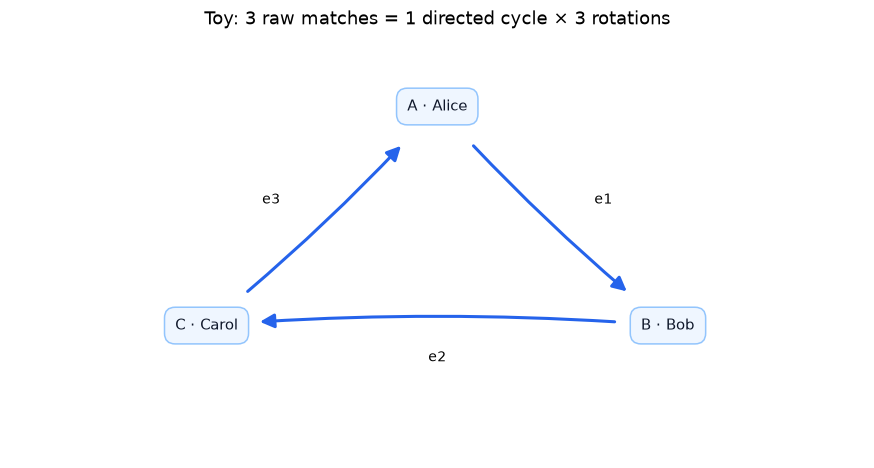

In [13]:
toy = build_toy_graph(spark)
display(toy.vertices.orderBy('id').toPandas())
display(toy.edges.orderBy('src').toPandas())
toy_result = run_demo(spark)
display(pd.DataFrame(toy_result['raw_matches'],columns=['a','b','c']))
assert (toy_result['raw_match_count'],toy_result['unique_cycle_count']) == (3,1)
draw_graph({'A':'A · Alice','B':'B · Bob','C':'C · Carol'},
    [('A','B','e1'),('B','C','e2'),('C','A','e3')],'Toy: 3 raw matches = 1 directed cycle × 3 rotations')
checks_passed['Toy graph.find: 3 rotations / 1 cycle'] = True


## 3 · Motif trên full IBM HI-Small

| Query | Điều kiện | Ý nghĩa |
|---|---|---|
| Audit nhãn | Ba cạnh thuộc graph `isFraud=1` | Kiểm tra cấu trúc **đã gắn nhãn**, không đánh giá detector |
| USD không dùng nhãn | Mọi cạnh `payment_currency='US Dollar'`, `amount>10.000` | Rule theo tiền có đơn vị thống nhất, không lọc isFraud |

Phân biệt **raw rows**, **bộ ba có thứ tự**, **cycle tài khoản có hướng**, **tổ hợp cạnh** và **bộ ba không xét chiều**. Đa cạnh tăng tổ hợp giao dịch; hướng ngược là một cycle có hướng khác. Hai hàm dưới đây triển khai đầy đủ hai cách lọc/đếm.


In [14]:
# Khử phép xoay, giữ bội số giao dịch; áp USD threshold trên mọi cạnh mà không dùng nhãn.
# Production: src/ibm_aml/motif_finding.py

def directed_account_cycles(matches: DataFrame) -> DataFrame:
    """Keep one rotation per directed account cycle, retaining edge multiplicity."""
    return matches.where(
        (F.col("a.id") < F.col("b.id")) & (F.col("a.id") < F.col("c.id"))
    ).select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
    ).groupBy("a", "b", "c").agg(
        F.count("*").alias("transaction_combinations")
    )

def find_usd_cycles(graph: GraphFrame, minimum_amount: float) -> DataFrame:
    """Find label-blind cycles with all three payments strictly above a USD threshold."""
    if not math.isfinite(minimum_amount) or minimum_amount < 0:
        raise ValueError("minimum USD amount must be finite and >= 0")
    edges = graph.edges.where(
        (F.col("payment_currency") == "US Dollar")
        & (F.col("amount") > minimum_amount)
    )
    return find_three_node_cycles(GraphFrame(graph.vertices, edges))


### Kiểm tra khử phép xoay, đa cạnh và ngưỡng USD

Hai hướng ngược nhau là hai cycle có hướng khác nhau. Giao dịch lặp làm tăng tổ hợp cạnh; self-loop và đường đóng qua hai tài khoản không tạo cycle ba đỉnh. Query USD phải áp điều kiện tiền tệ/ngưỡng trên **cả ba cạnh** và không được vô tình lọc theo nhãn.


In [15]:
# Hai hướng cycle, một cặp đa cạnh và một self-loop.
vertices = spark.sql("SELECT * FROM VALUES ('A'),('B'),('C') AS v(id)")
edges = spark.sql(
    "SELECT * FROM VALUES ('A','B'),('A','B'),('B','C'),('C','A'),"
    "('A','C'),('C','B'),('B','A'),('A','A') AS e(src,dst)"
)
matches = find_three_node_cycles(GraphFrame(vertices, edges))
assert matches.count() == 9
assert sorted(row.transaction_combinations for row in directed_account_cycles(matches).collect()) == [1, 2]

# Chỉ nhóm A-B-C thỏa đủ ba cạnh USD >10.000, dù nhãn là 0/1 xen kẽ.
usd_vertices = spark.sql(
    "SELECT * FROM VALUES ('A'),('B'),('C'),('D'),('E'),('F'),('G'),('H'),('I') AS v(id)"
)
usd_edges = spark.sql(
    "SELECT * FROM VALUES "
    "('A','B',11000.0,'US Dollar',0),('B','C',12000.0,'US Dollar',1),('C','A',13000.0,'US Dollar',0),"
    "('D','E',11000.0,'US Dollar',1),('E','F',10000.0,'US Dollar',1),('F','D',13000.0,'US Dollar',1),"
    "('G','H',11000.0,'US Dollar',1),('H','I',12000.0,'Euro',1),('I','G',13000.0,'US Dollar',1) "
    "AS e(src,dst,amount,payment_currency,isFraud)"
)
usd_graph = GraphFrame(usd_vertices, usd_edges)
valid = directed_account_cycles(find_usd_cycles(usd_graph, 10_000)).collect()
assert [(row.a, row.b, row.c) for row in valid] == [('A', 'B', 'C')]
print('PASS: rotations, opposite orientations, parallel edges and label-blind USD rule.')
checks_passed['IBM motifs: rotations, multiplicity and all-edge USD threshold'] = True


PASS: rotations, opposite orientations, parallel edges and label-blind USD rule.


In [16]:
ibm_loaded = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
ibm = GraphFrame(ibm_loaded.vertices.select('id').cache(),ibm_loaded.edges.select(
    'src','dst','isFraud','payment_currency','amount').cache())
ibm_v,ibm_e = ibm.vertices.count(),ibm.edges.count()
assert (ibm_v,ibm_e) == (518_581,5_078_345)
fraud_edges = ibm.edges.where(F.col('isFraud')==1).cache()
fraud_count = fraud_edges.count()
fraud_matches = find_three_node_cycles(GraphFrame(ibm.vertices,fraud_edges)).cache()
raw_cycle_count = fraud_matches.count()
ordered_triples = fraud_matches.select('a.id','b.id','c.id').distinct().count()
unordered_sets = fraud_matches.select(F.array_sort(F.array('a.id','b.id','c.id')).alias('accounts')).distinct().count()
directed = directed_account_cycles(fraud_matches).cache()
directed_count = directed.count()
transaction_combinations = directed.agg(F.sum('transaction_combinations')).first()[0]
usd_raw_count = find_usd_cycles(ibm,10_000.0).count()
ibm_cycles = directed.orderBy(F.desc('transaction_combinations'),'a','b','c').toPandas()
fraud_currencies = fraud_edges.groupBy('payment_currency').agg(F.count('*').alias('fraud_edges')).orderBy(
    F.desc('fraud_edges'),'payment_currency').toPandas()
ibm_metrics = {'scope':'full','vertices':ibm_v,'edges':ibm_e,'fraud_edges':fraud_count,
    'raw_cycle_rows':raw_cycle_count,'ordered_triples':ordered_triples,
    'directed_account_cycles':directed_count,'transaction_combinations':transaction_combinations,
    'unordered_account_sets':unordered_sets,'usd_label_blind_raw_cycles':usd_raw_count}
assert raw_cycle_count == 3*transaction_combinations
assert ordered_triples == 3*directed_count
assert (fraud_count,raw_cycle_count,directed_count,transaction_combinations,unordered_sets,usd_raw_count) == (
    5177,7473,54,2491,45,0)
for result,relative in [(ibm_cycles,'results/ibm_aml/fraud_directed_cycles.csv'),
                         (fraud_currencies,'results/ibm_aml/fraud_currency_counts.csv')]:
    baseline = pd.read_csv(REPO_ROOT/relative)
    keys = list(result.columns)
    pd.testing.assert_frame_equal(result.sort_values(keys).reset_index(drop=True),
        baseline[keys].sort_values(keys).reset_index(drop=True),check_dtype=False,check_exact=True)
display(pd.DataFrame([ibm_metrics]))
display(ibm_cycles.head(10))
display(fraud_currencies)
checks_passed['Task 3 IBM full: rotations, multiplicity, currency and exact CSVs'] = True


,scope,vertices,edges,fraud_edges,raw_cycle_rows,ordered_triples,directed_account_cycles,transaction_combinations,unordered_account_sets,usd_label_blind_raw_cycles
0,full,518581,5078345,5177,7473,162,54,2491,45,0


,a,b,c,transaction_combinations
0,119_811C597B0,222_811B83280,48309_811C599A0,490
1,148350_811FFF630,148350_812D0C3C0,50528_812D0C600,360
2,119_811C597B0,150240_812D22980,48309_811C599A0,300
3,119_811C597B0,48309_811C599A0,150240_812D22980,280
4,119_811C597B0,222_811B83280,150240_812D22980,245
5,150240_812D22980,222_811B83280,48309_811C599A0,196
6,148350_811FFF630,50528_812D0C600,148350_812D0C3C0,160
7,119_811C597B0,48309_811C599A0,222_811B83280,150
8,150240_812D22980,48309_811C599A0,222_811B83280,150
9,119_811C597B0,150240_812D22980,222_811B83280,105


,payment_currency,fraud_edges
0,US Dollar,1912
1,Euro,1372
2,Saudi Riyal,374
3,Swiss Franc,193
4,Yuan,184
5,Rupee,167
6,Yen,155
7,Ruble,133
8,UK Pound,132
9,Canadian Dollar,128


### Cycle minh họa có giao dịch nguồn

Đọc 9 kịch bản cycle 3-hop trong Patterns, chọn ví dụ ba tài khoản khác nhau, thời gian tăng nghiêm ngặt, cùng loại tiền và xuất hiện trong CSV motif. Ví dụ dùng **Saudi Riyal (SAR)**; không được gọi đó là kết quả query USD. Số kịch bản cấy sẵn cũng không đồng nghĩa số cycle tổ hợp tìm được.


In [17]:
TIME_FORMAT = "%Y/%m/%d %H:%M"


In [18]:
# Đọc Patterns và chọn ví dụ đúng thời gian/currency có trong CSV motif, không xuất file.
# Production: src/ibm_aml/visualize.py

def read_three_account_cycles(path: Path) -> list[list[dict]]:
    """Read source rows, normalizing bank IDs exactly as the IBM ETL does."""
    cycles = []
    current = None
    for line_number, line in enumerate(
        path.read_text(encoding="utf-8-sig").splitlines(), 1
    ):
        if line.startswith("BEGIN LAUNDERING ATTEMPT"):
            current = [] if line == "BEGIN LAUNDERING ATTEMPT - CYCLE:  Max 3 hops" else None
        elif line.startswith("END LAUNDERING ATTEMPT"):
            if current is not None:
                if len(current) != 3:
                    raise ValueError(f"Expected three payments before source line {line_number}")
                cycles.append(current)
            current = None
        elif current is not None and line[:4].isdigit():
            values = next(csv.reader([line]))
            if len(values) != 11:
                raise ValueError(f"Invalid transaction at source line {line_number}")
            current.append({
                "src": f"{int(values[1])}_{values[2]}",
                "dst": f"{int(values[3])}_{values[4]}",
                "timestamp": datetime.strptime(values[0], TIME_FORMAT),
                "amount": Decimal(values[7]),
                "payment_currency": values[8],
                "amount_received": Decimal(values[5]),
                "receiving_currency": values[6],
                "payment_format": values[9],
                "isFraud": int(values[10]),
                "source_line": line_number,
            })
    return cycles

def select_example(cycles: list[list[dict]], cycle_csv: Path) -> list[dict]:
    """Choose the first chronological, same-currency >10k labeled source cycle.

    Require its directed account cycle to appear in the existing motif output.
    The threshold is in the original currency, not a converted USD threshold.
    """
    with cycle_csv.open(newline="", encoding="utf-8-sig") as stream:
        account_cycles = {(r["a"], r["b"], r["c"]) for r in csv.DictReader(stream)}
    for payments in cycles:
        accounts = tuple(payment["src"] for payment in payments)
        if len(set(accounts)) != 3:
            continue
        if any(payments[i]["dst"] != payments[(i + 1) % 3]["src"] for i in range(3)):
            continue
        if not (payments[0]["timestamp"] < payments[1]["timestamp"] < payments[2]["timestamp"]):
            continue
        if not all(p["isFraud"] == 1 and p["amount"] > Decimal("10000") for p in payments):
            continue
        if len({p["payment_currency"] for p in payments}) != 1:
            continue
        rotations = [accounts[i:] + accounts[:i] for i in range(3)]
        if min(rotations) in account_cycles:
            return payments
    raise ValueError("No suitable documented cycle also present in the motif CSV")


,src,dst,timestamp,amount,payment_currency,amount_received,receiving_currency,payment_format,isFraud,source_line,matching_input_rows
0,148350_811FFF630,148350_812D0C3C0,2022-09-05 18:42:00,48308.70,Saudi Riyal,48308.70,Saudi Riyal,ACH,1,2070,1
1,148350_812D0C3C0,50528_812D0C600,2022-09-07 12:52:00,43816.98,Saudi Riyal,43816.98,Saudi Riyal,ACH,1,2071,1
2,50528_812D0C600,148350_811FFF630,2022-09-07 18:12:00,42928.76,Saudi Riyal,42928.76,Saudi Riyal,ACH,1,2072,1


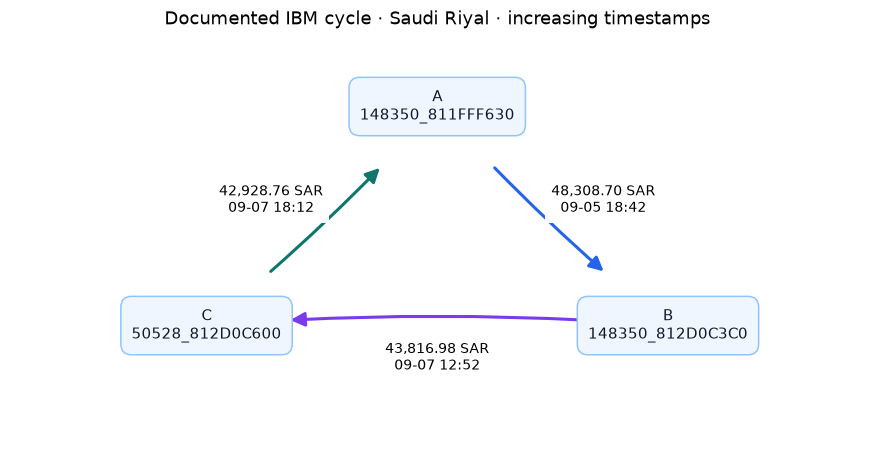

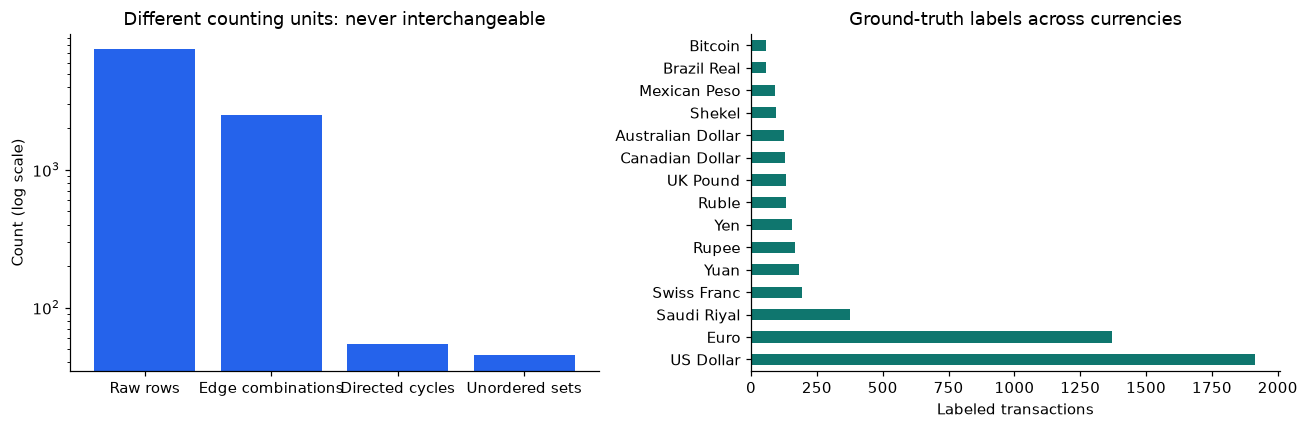

In [19]:
pattern_cycles = read_three_account_cycles(REPO_ROOT/'data/raw/ibm_aml/HI-Small_Patterns.txt')
payments = select_example(pattern_cycles,REPO_ROOT/'results/ibm_aml/fraud_directed_cycles.csv')
assert len(pattern_cycles) == 9
source_verification = []
for payment in payments:
    # Xác nhận từng cạnh ví dụ có trong input hiện tại; không suy đoán từ ảnh có sẵn.
    matches = ibm_loaded.edges.where(
        (F.col('src')==payment['src']) & (F.col('dst')==payment['dst']) &
        (F.col('timestamp')==F.lit(payment['timestamp'])) &
        (F.col('amount')==float(payment['amount'])) &
        (F.col('payment_currency')==payment['payment_currency']) & (F.col('isFraud')==1)).count()
    assert matches >= 1, payment
    source_verification.append({**payment,'matching_input_rows':matches})
display(pd.DataFrame(source_verification))
nodes = {letter:letter+'\n'+payment['src'] for letter,payment in zip('ABC',payments)}
edges = [(letter,'ABC'[(i+1)%3],f"{p['amount']:,.2f} SAR\n{p['timestamp']:%m-%d %H:%M}")
         for i,(letter,p) in enumerate(zip('ABC',payments))]
draw_graph(nodes,edges,'Documented IBM cycle · Saudi Riyal · increasing timestamps',
           colors=['#2563eb','#7c3aed','#0f766e'])
fig,axes = plt.subplots(1,2,figsize=(12,4))
axes[0].bar(['Raw rows','Edge combinations','Directed cycles','Unordered sets'],
    [raw_cycle_count,transaction_combinations,directed_count,unordered_sets],color='#2563eb')
axes[0].set(yscale='log',ylabel='Count (log scale)',title='Different counting units: never interchangeable')
fraud_currencies.plot.barh(x='payment_currency',y='fraud_edges',ax=axes[1],legend=False,color='#0f766e')
axes[1].set(xlabel='Labeled transactions',ylabel='',title='Ground-truth labels across currencies')
plt.tight_layout()
plt.show()
fraud_matches.unpersist()
fraud_edges.unpersist()
directed.unpersist()
ibm.vertices.unpersist()
ibm.edges.unpersist()
spark.catalog.clearCache()
checks_passed['IBM documented cycle: source, time order and original currency'] = True


## 4 · Detector cycle IBM không dùng nhãn và hiệu chỉnh có bằng chứng

**H1 — USD >10.000 đại diện tốt cho vòng rửa tiền:** kiểm tra cấu trúc không dùng nhãn, sau đó lượng hóa phần bị bỏ qua vì currency và amount.

**H2 — cycle khép kín theo thời gian, cùng currency, số tiền tương đồng là tín hiệu hữu ích:** tìm `A → B → C → A` trên **toàn graph không có nhãn**. Đồ thị topology gộp đa cạnh trước để tìm bộ tài khoản; sau đó nối lại đầy đủ giao dịch thực, xét **cả ba phép xoay** để không loại nhầm vòng có cạnh sớm nhất bắt đầu ở ID khác.

Tại `t3`, cạnh thứ ba là **giao dịch được cảnh báo**; `t1 < t2 < t3` là bằng chứng đã quan sát. Không đánh ngược nhãn dự đoán cho hai cạnh quá khứ rồi báo thành ba TP. Số tổ hợp giao dịch và số cảnh báo duy nhất được báo riêng.

Grid cố định: cửa sổ **1 / 6 / 24 / 72 / 168 / 504 giờ** × `min(amount)/max(amount)` tối thiểu **0 / 0,5 / 0,8 / 0,95** × floor **0 / q50 / q90** từ training **của chính currency đó** = **72 rule**. Không chọn riêng Saudi Riyal dựa vào nhãn.

Chỉ xét ba cạnh cùng payment currency, mỗi cạnh không đổi receiving currency. Loại FX và timestamp bằng nhau vì chưa đủ cơ sở truy vết dòng tiền; ghi rõ đây là giới hạn recall. Ratio là độ tương đồng số tiền, không chứng minh bảo toàn một khoản tiền. So với baseline **mọi cycle cùng currency theo thời gian**, và baseline USD cũ.

Nguồn ý nghĩa dữ liệu: [IBM AML-Data](https://github.com/IBM/AML-Data), [bài báo AMLworld](https://arxiv.org/html/2306.16424v3). Các số liệu dưới đây đều được tính từ input của project.


### Quy trình đánh giá và tiêu chí chọn ngưỡng (khóa trước khi chạy)

1. Gắn ID **cho từng dòng giao dịch**, giữ cả các dòng trùng nội dung. ID chỉ có ý nghĩa trong lần chạy này.
2. Chia khoảng **60% / 20% / 20% theo thời gian**, giữ mọi giao dịch cùng timestamp trong cùng tập. In ranh giới và số lượng thực tế, không giả định các tập có cùng tỷ lệ fraud.
3. Học ngưỡng phân vị tiền từ **training không có nhãn**; chọn rule bằng **F1 trên validation**, sau đó precision, ít FP hơn, và ID rule để phá hòa. Không tối ưu accuracy vì dữ liệu mất cân bằng.
4. Khóa rule rồi mới đánh giá test. TP/FP/FN/TN tính theo **giao dịch ra quyết định duy nhất**, không tính theo số tổ hợp motif. Mẫu số gồm **mọi giao dịch**, kể cả loại mà rule không hỗ trợ.
5. Nhãn chỉ đi vào audit và scorer; feature builder từ chối nhận `isFraud`/`isLaundering`. Không có TP trên validation thì **abstain**, không tự nới ngưỡng để ép ra fraud.

`isFraud` là ground truth. `alert=1` là đề nghị kiểm tra; `alert=0` không chứng minh giao dịch hợp pháp. Precision không xác định khi không có alert; recall không xác định khi không có fraud. Ngưỡng được gọi là **tốt nhất trong grid theo validation**, không phải tối ưu toàn cục.

Đây là **internal temporal holdout** của dataset đã được khám phá trong project, không phải benchmark ngoài mẫu hoàn toàn mới. Một lần chia thời gian chưa đo được độ ổn định hay khả năng áp dụng vào ngân hàng thật. Khung thời gian tham khảo cách đánh giá của [nhóm tác giả IBM AMLworld](https://arxiv.org/html/2306.16424v3#S4); mô hình ở đây là rule motif, không sao chép kết quả của họ.


In [20]:
# Production: src/motif/evaluation.py — đầy đủ code đang được thực thi

def require_unlabelled(frame: DataFrame) -> None:
    """Fail closed if a feature/query path accidentally receives ground truth."""
    forbidden = {"isfraud", "islaundering", "isflaggedfraud", "label", "target"}
    leaked = forbidden.intersection(name.lower() for name in frame.columns)
    if leaked:
        raise ValueError(f"Ground truth in feature builder: {sorted(leaked)}")


def index_transactions(edges: DataFrame) -> DataFrame:
    """Assign one run-local ID per physical row, including identical records.

    Materializing once freezes IDs before self-joins. These are not persistent
    transaction IDs and must not be compared across independent Spark runs.
    """
    if "event_id" in edges.columns:
        raise ValueError("event_id already exists")
    return edges.withColumn("event_id", F.monotonically_increasing_id()).localCheckpoint(eager=True)


def temporal_cutoffs(features: DataFrame) -> tuple[int, int]:
    """Approximately 60/20/20 by row count; keep timestamp ties in one split."""
    require_unlabelled(features)
    cuts = features.approxQuantile("step", [0.6, 0.8], 0.001)
    if len(cuts) != 2 or cuts[0] >= cuts[1]:
        raise ValueError("Need two distinct timestamp boundaries")
    return int(cuts[0]), int(cuts[1])


def split_expression(cutoffs: tuple[int, int]):
    """The same predicate is used for features and ground-truth denominators."""
    first, second = cutoffs
    if first >= second:
        raise ValueError("Temporal boundaries must increase")
    return F.when(F.col("step") <= first, "train").when(
        F.col("step") <= second, "validation"
    ).otherwise("test")


In [21]:
# Production: src/motif/evaluation.py — đầy đủ code đang được thực thi

def binary_metrics(total: int, positives: int, tp: int, fp: int) -> dict:
    """No accuracy shortcut; undefined precision/recall remain explicitly None."""
    values = (total, positives, tp, fp)
    if any(not math.isfinite(v) or int(v) != v or v < 0 for v in values):
        raise ValueError("Confusion counts must be finite nonnegative integers")
    if positives > total or tp > positives or fp > total - positives:
        raise ValueError("Inconsistent confusion matrix")
    fn, tn = int(positives - tp), int(total - positives - fp)
    alerts = int(tp + fp)
    return {
        "transactions": int(total), "fraud": int(positives),
        "alerts": alerts, "TP": int(tp), "FP": int(fp), "FN": fn, "TN": tn,
        "precision": tp / alerts if alerts else None,
        "recall": tp / positives if positives else None,
        "F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else None,
        "prevalence": positives / total if total else None,
        "alert_rate": alerts / total if total else None,
    }


def evaluate_alerts(alerts: DataFrame, truth: DataFrame) -> pd.DataFrame:
    """One prediction per transaction, never one per motif combination.

    truth has event_id, split, isFraud. Denominators include *all* transactions,
    including types/currencies that a particular motif cannot reach.
    """
    ids = alerts.select("event_id").distinct().withColumn("alert", F.lit(1))
    counts = truth.join(ids, "event_id", "left").groupBy("split").agg(
        F.count("*").alias("total"), F.sum("isFraud").alias("positives"),
        F.sum(F.when((F.col("alert") == 1) & (F.col("isFraud") == 1), 1).otherwise(0)).alias("tp"),
        F.sum(F.when((F.col("alert") == 1) & (F.col("isFraud") == 0), 1).otherwise(0)).alias("fp"),
    ).collect()
    records = [{"split": row.split, **binary_metrics(row.total, row.positives, row.tp, row.fp)}
               for row in counts]
    return pd.DataFrame(records).set_index("split").reindex(["train", "validation", "test"]).reset_index()


def select_validation_rule(scores: pd.DataFrame) -> dict:
    """Maximize validation F1, then precision, fewer FP, stable rule ID.

    The caller passes only validation scores. No supported true positive means
    abstain, rather than selecting an arbitrary rule merely to emit alerts.
    """
    if scores.empty or not (scores["TP"] > 0).any():
        return {"rule_id": "abstain", "reason": "No validation true positive; no supported threshold"}
    ranked = scores.assign(
        _f1=scores["F1"].fillna(-1), _precision=scores["precision"].fillna(-1)
    ).sort_values(["_f1", "_precision", "FP", "rule_id"], ascending=[False, False, True, True])
    return ranked.iloc[0].drop(labels=["_f1", "_precision"]).to_dict()


In [22]:
# Production: src/ibm_aml/motif_finding.py — đầy đủ code đang được thực thi

def find_topological_cycles(vertices: DataFrame, features: DataFrame) -> DataFrame:
    """Enumerate directed account triples once, without labels or amounts.

    Collapsing parallel edges *before* motif matching avoids multiplying every
    historical transaction combination during the topology discovery stage.
    """
    require_unlabelled(features)
    topology = features.where(F.col("src") != F.col("dst")).select("src", "dst").distinct()
    matches = find_three_node_cycles(GraphFrame(vertices.select("id"), topology))
    return matches.where(
        (F.col("a.id") < F.col("b.id")) & (F.col("a.id") < F.col("c.id"))
    ).selectExpr("a.id a", "b.id b", "c.id c")


def build_temporal_cycle_features(topology: DataFrame, features: DataFrame) -> DataFrame:
    """All three rotations, but only strictly chronological same-currency cycles.

    The last edge is the decision event; the other two are already observable.
    No currency conversion is inferred. FX edges and equal timestamps are
    excluded explicitly. Each returned row is evidence, not an independent TP.
    """
    require_unlabelled(features)
    edges = features.where(
        (F.col("src") != F.col("dst")) & (F.col("amount") > 0)
        & (F.col("payment_currency") == F.col("receiving_currency"))
    ).select("event_id", "src", "dst", "step", "amount", "payment_currency")
    result = None
    for rotation in range(3):
        names = ["a", "b", "c"]
        order = names[rotation:] + names[:rotation]
        query = topology.select(*(F.col(old).alias(new) for old, new in zip(order, names)))
        query = query.join(edges.alias("x"), (F.col("a") == F.col("x.src")) & (F.col("b") == F.col("x.dst")))
        query = query.join(edges.alias("y"),
            (F.col("b") == F.col("y.src")) & (F.col("c") == F.col("y.dst"))
            & (F.col("x.payment_currency") == F.col("y.payment_currency"))
            & (F.col("x.step") < F.col("y.step")))
        query = query.join(edges.alias("z"),
            (F.col("c") == F.col("z.src")) & (F.col("a") == F.col("z.dst"))
            & (F.col("x.payment_currency") == F.col("z.payment_currency"))
            & (F.col("y.step") < F.col("z.step")))
        flat = query.select(
            "a", "b", "c", F.col("z.event_id").alias("event_id"),
            F.col("x.event_id").alias("first_event_id"), F.col("y.event_id").alias("second_event_id"),
            F.col("x.step").alias("first_step"), F.col("y.step").alias("second_step"),
            F.col("z.step").alias("step"), F.col("x.payment_currency").alias("payment_currency"),
            F.col("x.amount").alias("first_amount"), F.col("y.amount").alias("second_amount"),
            F.col("z.amount").alias("amount"),
            (F.col("z.step") - F.col("x.step")).alias("gap_seconds"),
            F.least("x.amount", "y.amount", "z.amount").alias("minimum_cycle_amount"),
            (F.least("x.amount", "y.amount", "z.amount") / F.greatest(
                "x.amount", "y.amount", "z.amount")).alias("amount_ratio"),
        )
        result = flat if result is None else result.unionByName(flat)
    return result


In [23]:
# Production: src/ibm_aml/motif_finding.py — đầy đủ code đang được thực thi

def cycle_training_thresholds(features: DataFrame, train_end: int) -> DataFrame:
    """Per-currency training quantiles, without comparing nominal currency units."""
    require_unlabelled(features)
    return features.where((F.col("step") <= train_end) & (F.col("amount") > 0)).groupBy(
        "payment_currency"
    ).agg(F.percentile_approx("amount", [0.5, 0.9], 10_000).alias("_quantiles"),
          F.count("*").alias("training_transactions")).select(
        "payment_currency", "training_transactions",
        F.col("_quantiles")[0].alias("q50_amount"), F.col("_quantiles")[1].alias("q90_amount"),
    )


def temporal_cycle_alerts(candidates: DataFrame, rule: dict) -> DataFrame:
    """Return evidence rows; callers deduplicate event_id before counting alerts."""
    require_unlabelled(candidates)
    if rule["rule_id"] == "abstain":
        return candidates.where(F.lit(False))
    quantile = float(rule["quantile"])
    floor = F.lit(0.0) if quantile == 0 else F.col("q50_amount" if quantile == 0.5 else "q90_amount")
    return candidates.where(
        (F.col("gap_seconds") <= float(rule["window_hours"]) * 3600)
        & (F.col("amount_ratio") >= float(rule["minimum_ratio"]))
        & (F.col("minimum_cycle_amount") > floor)
    )


def score_cycle_validation(candidates: DataFrame, truth: DataFrame):
    """Fixed 72-rule grid; score unique closing transactions on validation only."""
    import pandas as pd

    require_unlabelled(candidates)
    validation = truth.where(F.col("split") == "validation")
    support = validation.agg(F.count("*").alias("n"), F.sum("isFraud").alias("p")).first()
    if not support.n:
        raise ValueError("Empty validation split")
    evidence = candidates.where(F.col("split") == "validation").join(
        validation.select("event_id", "isFraud"), "event_id"
    ).toPandas()
    records = []
    for hours in (1, 6, 24, 72, 168, 504):
        for ratio in (0.0, 0.5, 0.8, 0.95):
            for quantile in (0.0, 0.5, 0.9):
                floor = 0.0 if quantile == 0 else evidence["q50_amount" if quantile == 0.5 else "q90_amount"]
                mask = (evidence.gap_seconds <= hours * 3600) & (evidence.amount_ratio >= ratio) & (
                    evidence.minimum_cycle_amount > floor
                )
                selected = evidence.loc[mask].drop_duplicates("event_id")
                tp, n = int(selected.isFraud.sum()), len(selected)
                records.append({
                    "rule_id": f"cycle_h{hours:03d}_r{ratio:.2f}_q{quantile:.1f}",
                    "window_hours": hours, "minimum_ratio": ratio, "quantile": quantile,
                    **binary_metrics(support.n, support.p, tp, n - tp),
                })
    return pd.DataFrame(records)


In [24]:
# Các biến fraud_* phía trên là audit baseline; không đi vào detector này.
fraud_matches.unpersist();directed.unpersist();fraud_edges.unpersist()
ibm.vertices.unpersist();ibm.edges.unpersist();spark.catalog.clearCache()
ibm_indexed = index_transactions(ibm_loaded.edges.select(
    'src','dst','step','amount','payment_currency','receiving_currency','isFraud'))
ibm_features = ibm_indexed.drop('isFraud')
ibm_cutoffs = temporal_cutoffs(ibm_features)
ibm_features = ibm_features.withColumn('split',split_expression(ibm_cutoffs))
ibm_truth = ibm_indexed.withColumn('split',split_expression(ibm_cutoffs)).select('event_id','split','isFraud')
display(pd.DataFrame([{'train_end_epoch_seconds':ibm_cutoffs[0],
    'validation_end_epoch_seconds':ibm_cutoffs[1],
    'train_end_utc':datetime.fromtimestamp(ibm_cutoffs[0],timezone.utc).isoformat(),
    'validation_end_utc':datetime.fromtimestamp(ibm_cutoffs[1],timezone.utc).isoformat()}]))
display(ibm_truth.groupBy('split').agg(F.count('*').alias('transactions'),F.sum('isFraud').alias('fraud')).toPandas())
ibm_topology = find_topological_cycles(ibm_loaded.vertices,ibm_features).localCheckpoint(eager=True)
ibm_topology_count=ibm_topology.count()
print('Directed topology cycles, không lọc nhãn/currency/amount:',ibm_topology_count)
ibm_thresholds=cycle_training_thresholds(ibm_features,ibm_cutoffs[0])
display(ibm_thresholds.orderBy('payment_currency').toPandas())
ibm_temporal = build_temporal_cycle_features(ibm_topology,ibm_features).withColumn(
    'split',split_expression(ibm_cutoffs)).join(ibm_thresholds,'payment_currency','left').localCheckpoint(eager=True)
assert ibm_temporal.where('first_step>=second_step OR second_step>=step').count()==0
display(ibm_temporal.groupBy('payment_currency').agg(
    F.count('*').alias('evidence_combinations'),F.countDistinct('event_id').alias('unique_closing_transactions'),
    F.min('minimum_cycle_amount').alias('minimum_cycle_amount')).orderBy('payment_currency').toPandas())
ibm_validation_scores=score_cycle_validation(ibm_temporal,ibm_truth)
ibm_rule=select_validation_rule(ibm_validation_scores)
display(ibm_validation_scores.sort_values(['F1','precision'],ascending=False).head(12))
display(pd.DataFrame([ibm_rule]))
print('Đã khóa rule theo validation; test không tham gia chọn tham số.')


,train_end_epoch_seconds,validation_end_epoch_seconds,train_end_utc,validation_end_utc
0,1662446040,1662628320,2022-09-06T06:34:00+00:00,2022-09-08T09:12:00+00:00


,split,transactions,fraud
0,validation,1016257,1083
1,test,1015564,1797
2,train,3046524,2297


Directed topology cycles, không lọc nhãn/currency/amount: 563


,payment_currency,training_transactions,q50_amount,q90_amount
0,Australian Dollar,81862,1450.65000,7.155925e+04
1,Bitcoin,87164,0.07681,5.051369e+00
2,Brazil Real,42282,5634.50000,3.221040e+05
3,Canadian Dollar,83736,1244.61000,5.981860e+04
4,Euro,702593,822.24000,4.052427e+04
5,Mexican Peso,66247,20403.20000,1.028896e+06
6,Ruble,92866,75243.54000,4.270884e+06
7,Rupee,114085,70328.87000,4.552123e+06
8,Saudi Riyal,52978,3723.39000,2.033921e+05
9,Shekel,115095,3386.38000,1.585748e+05


,payment_currency,evidence_combinations,unique_closing_transactions,minimum_cycle_amount
0,Australian Dollar,12,11,331.720000
1,Bitcoin,31,18,0.003677
2,Brazil Real,3,3,2526.070000
3,Canadian Dollar,17,14,69.450000
4,Euro,50,47,66.900000
5,Mexican Peso,15,15,3079.960000
6,Ruble,5,5,26964.160000
7,Rupee,8,6,38724.540000
8,Saudi Riyal,1436,115,655.640000
9,Shekel,18,15,582.910000


,rule_id,window_hours,minimum_ratio,quantile,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate
48,cycle_h168_r0.00_q0.0,168,0.0,0.0,1016257,1083,102,29,73,1054,1015101,0.284314,0.026777,0.048945,0.001066,0.000100
60,cycle_h504_r0.00_q0.0,504,0.0,0.0,1016257,1083,108,29,79,1054,1015095,0.268519,0.026777,0.048699,0.001066,0.000106
49,cycle_h168_r0.00_q0.5,168,0.0,0.5,1016257,1083,62,26,36,1057,1015138,0.419355,0.024007,0.045415,0.001066,0.000061
61,cycle_h504_r0.00_q0.5,504,0.0,0.5,1016257,1083,64,26,38,1057,1015136,0.406250,0.024007,0.045336,0.001066,0.000063
36,cycle_h072_r0.00_q0.0,72,0.0,0.0,1016257,1083,39,22,17,1061,1015157,0.564103,0.020314,0.039216,0.001066,0.000038
51,cycle_h168_r0.50_q0.0,168,0.5,0.0,1016257,1083,36,18,18,1065,1015156,0.500000,0.016620,0.032172,0.001066,0.000035
63,cycle_h504_r0.50_q0.0,504,0.5,0.0,1016257,1083,37,18,19,1065,1015155,0.486486,0.016620,0.032143,0.001066,0.000036
37,cycle_h072_r0.00_q0.5,72,0.0,0.5,1016257,1083,24,17,7,1066,1015167,0.708333,0.015697,0.030714,0.001066,0.000024
52,cycle_h168_r0.50_q0.5,168,0.5,0.5,1016257,1083,33,17,16,1066,1015158,0.515152,0.015697,0.030466,0.001066,0.000032
64,cycle_h504_r0.50_q0.5,504,0.5,0.5,1016257,1083,34,17,17,1066,1015157,0.500000,0.015697,0.030439,0.001066,0.000033


,rule_id,window_hours,minimum_ratio,quantile,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence,alert_rate
0,cycle_h168_r0.00_q0.0,168,0.0,0.0,1016257,1083,102,29,73,1054,1015101,0.284314,0.026777,0.048945,0.001066,0.0001


Đã khóa rule theo validation; test không tham gia chọn tham số.


### Đánh giá sau khi khóa và audit nguyên nhân baseline bỏ sót

Tất cả các mô hình dưới đây được so trên cùng tập giao dịch. Baseline USD được áp thêm cùng điều kiện thời gian để so công bằng với detector causal. Baseline USD cũ không yêu cầu thời gian đã có 0 ở phần trước.

Một cảnh báo chỉ được tính một lần dù có nhiều cặp giao dịch quá khứ làm bằng chứng. Recall dùng **tất cả fraud**, không chỉ fraud nằm trong cycle; nhiều typology IBM khác cycle ba đỉnh nằm ngoài khả năng rule này. Số liệu toàn tập dùng giải thích, số liệu test dùng đánh giá cấu hình đã khóa.


In [25]:
ibm_selected = temporal_cycle_alerts(ibm_temporal,ibm_rule).localCheckpoint(eager=True)
ibm_all_cycle_rule={'rule_id':'all_temporal_cycles','window_hours':504,'minimum_ratio':0.,'quantile':0.}
ibm_all_cycles=temporal_cycle_alerts(ibm_temporal,ibm_all_cycle_rule)
ibm_usd_baseline=ibm_temporal.where("payment_currency='US Dollar' AND minimum_cycle_amount>10000")
ibm_evaluations=pd.concat([
    evaluate_alerts(ibm_selected,ibm_truth).assign(model='calibrated cycle'),
    evaluate_alerts(ibm_all_cycles,ibm_truth).assign(model='all temporal cycles'),
    evaluate_alerts(ibm_usd_baseline,ibm_truth).assign(model='USD >10000 baseline'),
    evaluate_alerts(ibm_features.where(F.lit(False)),ibm_truth).assign(model='no-alert baseline'),
],ignore_index=True)
display(ibm_evaluations[['model','split','transactions','fraud','alerts','TP','FP','FN','TN','precision','recall','F1','prevalence']])
ibm_validation_check=ibm_evaluations.query("model=='calibrated cycle' and split=='validation'").iloc[0]
if ibm_rule['rule_id']!='abstain':
    assert (ibm_validation_check.TP,ibm_validation_check.FP)==(ibm_rule['TP'],ibm_rule['FP'])
# Audit nhãn sau truy vấn/selection: khác biệt combinations và closing transactions.
ibm_cycle_audit=ibm_temporal.join(ibm_truth.select('event_id','isFraud'),'event_id')
display(ibm_cycle_audit.groupBy('payment_currency').agg(
    F.count('*').alias('combinations'),F.countDistinct('event_id').alias('closing_transactions'),
    F.countDistinct(F.when(F.col('isFraud')==1,F.col('event_id'))).alias('fraud_closing_transactions')
).orderBy(F.desc('fraud_closing_transactions')).toPandas())
ibm_alert_details=ibm_selected.join(ibm_truth.select('event_id','isFraud'),'event_id')
for title,label in [('TP: cycle cảnh báo đúng nhãn',1),('FP: cycle cảnh báo nhưng nhãn normal',0)]:
    print(title)
    display(ibm_alert_details.where((F.col('split')=='test') & (F.col('isFraud')==label)).orderBy(
        'step','first_step').dropDuplicates(['event_id']).limit(3).toPandas())
print('FN: fraud test không được cảnh báo bởi cycle detector')
ibm_missed=ibm_features.join(ibm_selected.select('event_id').distinct(),'event_id','left_anti').join(
    ibm_truth.select('event_id','isFraud'),'event_id').where("split='test' AND isFraud=1")
display(ibm_missed.orderBy('step').limit(3).toPandas())
checks_passed['IBM: label-blind causal cycles, currency quantiles and frozen test evaluation'] = True


,model,split,transactions,fraud,alerts,TP,FP,FN,TN,precision,recall,F1,prevalence
0,calibrated cycle,train,3046524,2297,70,22,48,2275,3044179,0.314286,0.009578,0.018589,0.000754
1,calibrated cycle,validation,1016257,1083,102,29,73,1054,1015101,0.284314,0.026777,0.048945,0.001066
2,calibrated cycle,test,1015564,1797,132,41,91,1756,1013676,0.310606,0.022816,0.042509,0.001769
3,all temporal cycles,train,3046524,2297,70,22,48,2275,3044179,0.314286,0.009578,0.018589,0.000754
4,all temporal cycles,validation,1016257,1083,108,29,79,1054,1015095,0.268519,0.026777,0.048699,0.001066
5,all temporal cycles,test,1015564,1797,208,57,151,1740,1013616,0.274038,0.031720,0.056858,0.001769
6,USD >10000 baseline,train,3046524,2297,0,0,0,2297,3044227,None,0.000000,0.000000,0.000754
7,USD >10000 baseline,validation,1016257,1083,0,0,0,1083,1015174,None,0.000000,0.000000,0.001066
8,USD >10000 baseline,test,1015564,1797,0,0,0,1797,1013767,None,0.000000,0.000000,0.001769
9,no-alert baseline,train,3046524,2297,0,0,0,2297,3044227,None,0.000000,0.000000,0.000754


,payment_currency,combinations,closing_transactions,fraud_closing_transactions
0,Saudi Riyal,1436,115,105
1,US Dollar,98,92,2
2,Swiss Franc,16,16,1
3,Euro,50,47,0
4,Yen,15,12,0
5,Brazil Real,3,3,0
6,UK Pound,6,6,0
7,Yuan,12,11,0
8,Canadian Dollar,17,14,0
9,Bitcoin,31,18,0


TP: cycle cảnh báo đúng nhãn


,event_id,payment_currency,a,b,c,first_event_id,second_event_id,first_step,second_step,step,...,second_amount,amount,gap_seconds,minimum_cycle_amount,amount_ratio,split,training_transactions,q50_amount,q90_amount,isFraud
0,410130,Saudi Riyal,223_811A65E30,222_811D80C30,121_8000E1590,25770058999,25770083436,1662279900,1662604860,1662684660,...,51178.80,62690.22,404760,2023.38,0.032276,test,52978,3723.39,203392.06,1
1,576380,Saudi Riyal,119_81235E8B0,249176_81235EC40,223_812D1A410,1039071,8591100941,1662461640,1662871620,1662899400,...,53104.45,37845.11,437760,8812.42,0.165945,test,52978,3723.39,203392.06,1
2,589758,Saudi Riyal,119_811C597B0,48309_811C599A0,150240_812D22980,8590927506,25770826118,1662402960,1662462360,1662894120,...,66099.95,27043.63,491160,27043.63,0.001059,test,52978,3723.39,203392.06,1


FP: cycle cảnh báo nhưng nhãn normal


,event_id,payment_currency,a,b,c,first_event_id,second_event_id,first_step,second_step,step,...,second_amount,amount,gap_seconds,minimum_cycle_amount,amount_ratio,split,training_transactions,q50_amount,q90_amount,isFraud
0,507540,US Dollar,28827_8051536B0,1124_80512EF80,11474_80512E630,17180939816,17180980576,1662533160,1662580500,1662632280,...,878.72,4840.27,99120,878.72,0.181544,test,1136991,995.74,49708.50,0
1,516343,Yen,10581_80C45D0E0,110057_80C45D220,29467_80C45D1D0,8590740195,878304,1662078840,1662174600,1662648480,...,87306.98,514081.08,569640,87306.98,0.169831,test,93197,103453.19,5931894.48,0
2,536229,US Dollar,219860_80E388E40,11974_80E387130,795_80E38AE00,17180732717,8590822952,1662171840,1662290880,1662638040,...,2007.49,125.02,466200,125.02,0.037230,test,1136991,995.74,49708.50,0


FN: fraud test không được cảnh báo bởi cycle detector


,event_id,src,dst,step,amount,payment_currency,receiving_currency,split,isFraud
0,17180293675,212818_804A8A480,12_80C5C01D0,1662628380,56897.95,Mexican Peso,Mexican Peso,test,1
1,8591072641,2591_800AEAC00,1502_8009FD120,1662628560,261675.02,Euro,Euro,test,1
2,8590442918,16388_810FE30E0,16354_810FE4270,1662628740,1776.51,Euro,Euro,test,1


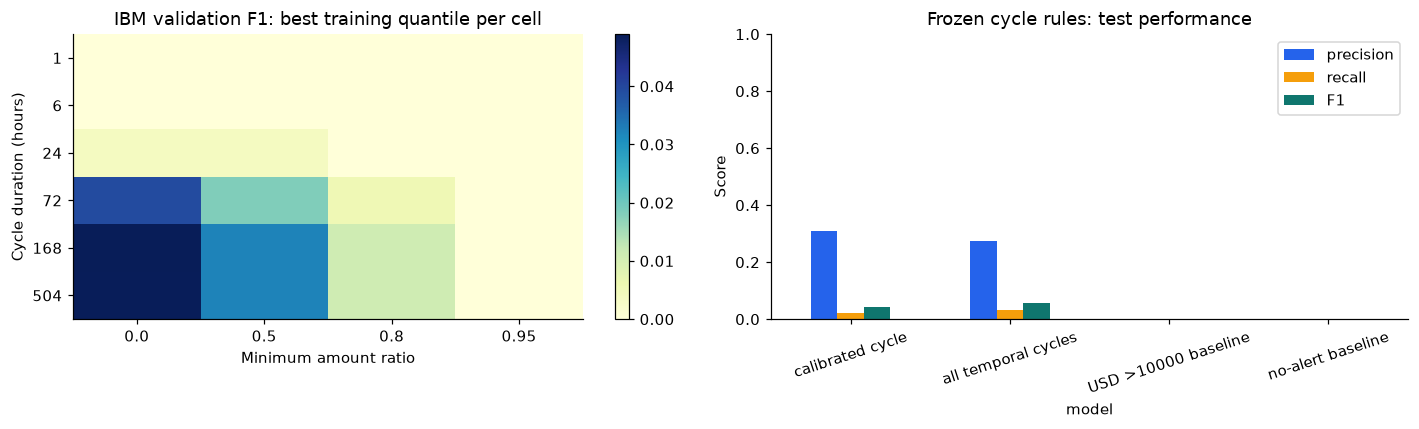

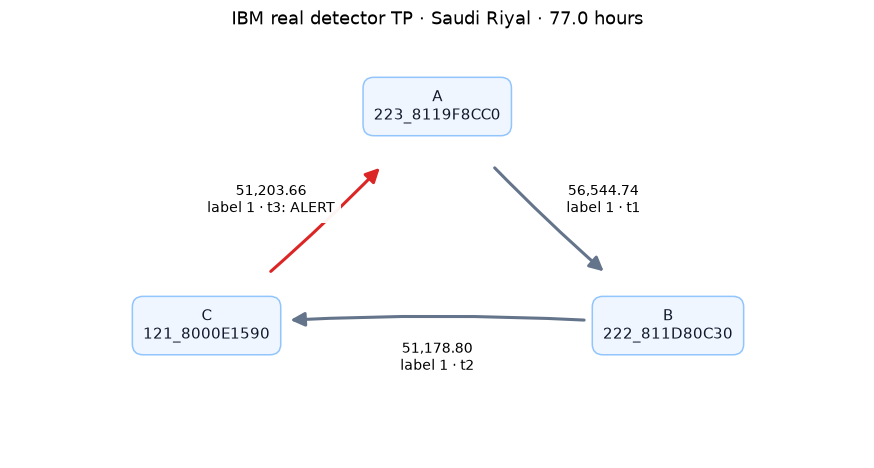

Cycle test: TP=41, FP=91, FN=1756.
Đây là cảnh báo cạnh đóng vòng; không phải nhãn dự đoán hồi tố cho cả ba cạnh.
F1 test cao hơn baseline mọi temporal cycle: False


In [26]:
heat=ibm_validation_scores.pivot_table(index='window_hours',columns='minimum_ratio',values='F1',aggfunc='max')
fig,axes=plt.subplots(1,2,figsize=(13,4))
image=axes[0].imshow(heat.values,aspect='auto',cmap='YlGnBu')
axes[0].set(xticks=range(len(heat.columns)),xticklabels=heat.columns,
            yticks=range(len(heat.index)),yticklabels=heat.index,xlabel='Minimum amount ratio',
            ylabel='Cycle duration (hours)',title='IBM validation F1: best training quantile per cell')
fig.colorbar(image,ax=axes[0])
comparison=ibm_evaluations.query("split=='test'").set_index('model')
comparison[['precision','recall','F1']].plot.bar(ax=axes[1],rot=18,color=['#2563eb','#f59e0b','#0f766e'])
axes[1].set(title='Frozen cycle rules: test performance',ylim=(0,1),ylabel='Score')
plt.tight_layout();plt.show()
# Chọn ví dụ từ chính output detector, không đọc Patterns để tạo một detection.
examples=ibm_alert_details.where("split='test' AND isFraud=1").orderBy('step','first_step').limit(1).collect()
if examples:
    row=examples[0]
    first_label=ibm_truth.where(F.col('event_id')==row.first_event_id).first().isFraud
    second_label=ibm_truth.where(F.col('event_id')==row.second_event_id).first().isFraud
    nodes={'A':'A\n'+row.a,'B':'B\n'+row.b,'C':'C\n'+row.c}
    draw_graph(nodes,[('A','B',f'{row.first_amount:,.2f}\nlabel {first_label} · t1'),
                      ('B','C',f'{row.second_amount:,.2f}\nlabel {second_label} · t2'),
                      ('C','A',f'{row.amount:,.2f}\nlabel {row.isFraud} · t3: ALERT')],
        f'IBM real detector TP · {row.payment_currency} · {row.gap_seconds/3600:.1f} hours',
        colors=['#64748b','#64748b','#dc2626'])
else:
    print('Không có TP trên test; không thay bằng ví dụ audit nhãn để giả lập detector.')
selected_test=comparison.loc['calibrated cycle']
print(f"Cycle test: TP={int(selected_test.TP)}, FP={int(selected_test.FP)}, FN={int(selected_test.FN)}.")
print('Đây là cảnh báo cạnh đóng vòng; không phải nhãn dự đoán hồi tố cho cả ba cạnh.')
print('F1 test cao hơn baseline mọi temporal cycle:',bool(selected_test.F1>comparison.loc['all temporal cycles'].F1))


### Kết luận từ lần chạy đã lưu

**563 cycle topology có hướng** được tìm trên graph không có nhãn. Nối giao dịch theo thời gian/currency cho **1.742 tổ hợp bằng chứng**, tương ứng **386 giao dịch đóng vòng duy nhất**, trong đó **108 giao dịch có nhãn laundering**. Đây là các đơn vị khác nhau; không báo 1.742 TP.

Validation chọn cửa sổ **168 giờ**, ratio tối thiểu **0**, amount floor **0**. Tức là trong grid đã khóa, validation **không ủng hộ thêm điều kiện số tiền gần bằng nhau hoặc floor cao** khi tối ưu F1 trên toàn giao dịch. Không tự thêm điều kiện để kết quả trông hợp lý hơn.

| Model đã khóa | Test TP | FP | FN | Precision | Recall | F1 |
|---|---:|---:|---:|---:|---:|---:|
| Cycle được chọn trên validation | 41 | 91 | 1.756 | 31,06% | 2,28% | 4,25% |
| Mọi temporal cycle trong 504 giờ | 57 | 151 | 1.740 | 27,40% | 3,17% | 5,69% |
| Baseline USD >10.000 | 0 | 0 | 1.797 | Không xác định | 0% | 0% |

Mẫu số test: **1.015.564 giao dịch / 1.797 laundering**. Cấu hình được chọn có precision cao hơn baseline rộng, nhưng F1 thấp hơn trên test; **chưa có bằng chứng optimizer cải thiện khả năng tổng quát hóa**. Giữ nguyên rule đã khóa, không chọn lại theo test.

**H1 bị bác bỏ như một điều kiện bao phủ tốt:** giao dịch đóng vòng mang nhãn laundering xuất hiện chủ yếu ngoài USD, đặc biệt ở Saudi Riyal; USD >10.000 bỏ hết ứng viên. **H2 được hỗ trợ ở mức tín hiệu điều tra**, vì truy vấn không lọc nhãn vẫn tìm được TP, nhưng không đủ cho detector tổng thể. Với cấu trúc/giới hạn thời gian/currency hiện tại, thậm chí baseline rộng chỉ có thể chạm **57/1.797 fraud test** ở vai trò cạnh đóng vòng. Không ngưỡng hẹp hơn nào vượt được giới hạn bao phủ đó trên tập này.

### Ý nghĩa cho PageRank/LPA và giới hạn còn lại

Cycle evidence có ID cạnh đang đánh giá, hai ID cạnh quá khứ, ba tài khoản, currency, thời gian, ratio và ngưỡng training. Dùng chúng làm feature có giải thích rồi join PageRank/LPA theo ID tài khoản từ **snapshot đến thời điểm quyết định**. Không dùng tỷ lệ fraud cộng đồng tính từ nhãn test làm feature.

Chỉ một cycle ba đỉnh không bao phủ cycle dài hơn, fan-in/fan-out hoặc các typology khác. Không cảnh báo không có nghĩa “không rửa tiền”. Các community thống kê phía sau là phần review LPA độc lập; chúng chưa được ghép thành detector kết hợp hay đánh giá bằng các số đo cycle ở trên.


In [27]:
# Nhường heap cho full LPA ở phần tiếp theo.
ibm_selected.unpersist();ibm_temporal.unpersist();ibm_topology.unpersist();ibm_indexed.unpersist()
spark.catalog.clearCache()


## 5 · Review và final LPA IBM

LPA cập nhật nhãn theo nhãn phổ biến trong lân cận:

$$L_v^{(t+1)}\in\operatorname{argmax}_{\ell}\sum_{u\in N(v)}\mathbf1[L_u^{(t)}=\ell].$$

Production dùng GraphFrames/GraphX `labelPropagation(maxIter=5)`. Chỉ đưa topology `id/src/dst` vào thuật toán rồi join lại metadata; giữ đa cạnh/self-loop của input. **Fraud/amount không tham gia bỏ phiếu**, chỉ dùng mô tả sau LPA. Label số có thể đổi giữa các lần chạy.

| Tiêu chí review | Kiểm tra |
|---|---|
| Checkpoint | `setCheckpointDir` trước LPA |
| Coverage | Mỗi account đúng một lần; không thiếu/thừa ID; label nguyên, không null |
| Metadata | bank_id/balance khớp input; balance IBM là placeholder |
| Profile | Đủ mọi community; members/banks/fraud/internal edges khớp input |
| Top 50 | Chỉ là view, không thay bảng đầy đủ |
| Amount | Group theo label **và payment_currency**, không cộng các loại tiền |
| Stability | So thành viên sau canonicalization, không so số label |

Hoàng phụ trách LPA; các cell tiếp theo chứa đầy đủ code đã được Khánh review/sửa và checker độc lập.


In [28]:
DEFAULT_CHECKPOINT_DIR = Path(runtime_temp.name)/'lpa_default'
COMMUNITIES_FILENAME = 'communities.csv'
COMMUNITY_SUMMARY_FILENAME = 'community_summary.csv'
COMMUNITY_SUMMARY_ALL_FILENAME = 'community_summary_all.csv'
COMMUNITY_AMOUNTS_FILENAME = 'community_amounts_by_currency.csv'


In [29]:
# LPA production đầy đủ: checkpoint, topology projection, labels join và cache.
# Production: src/ibm_aml/community_detection.py

def run_lpa(graph: GraphFrame, spark, max_iter: int = 5, checkpoint_dir: Path = DEFAULT_CHECKPOINT_DIR):
    """
    Thực thi Label Propagation Algorithm (LPA) trên IBM AML graph.
    """
    if max_iter <= 0:
        raise ValueError("max_iter must be > 0")
    checkpoint_dir.mkdir(parents=True, exist_ok=True)
    spark.sparkContext.setCheckpointDir(str(checkpoint_dir.resolve()))

    print(f"\n[*] Đang thực thi LPA trên IBM AML (maxIter={max_iter}) với checkpoint tại: {checkpoint_dir} ...")
    # LPA voting uses topology. Keep all parallel/self-loop edges, but avoid
    # carrying transaction attributes and vertex metadata through GraphX.
    topology = GraphFrame(graph.vertices.select("id"), graph.edges.select("src", "dst"))
    labels = topology.labelPropagation(maxIter=max_iter)
    lpa_result = graph.vertices.join(labels.select("id", "label"), on="id", how="inner")

    lpa_result.cache()
    total_labeled = lpa_result.count()
    labels.unpersist()
    print(f"[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: {total_labeled:,}")

    return lpa_result


In [30]:
# Community profiling đầy đủ, không cộng amount khác đơn vị vào một tổng chung.
# Production: src/ibm_aml/community_detection.py

def analyze_communities(lpa_vertices, graph: GraphFrame, top_n: int = 15):
    """
    Phân tích đặc trưng cộng đồng trong dữ liệu ngân hàng IBM AML:
      - Kích thước cộng đồng và số ngân hàng tham gia (bank diversity).
      - Tỷ lệ giao dịch nội bộ cộng đồng vs liên cộng đồng.
      - Phân bổ giao dịch rửa tiền (Is Laundering / isFraud).
    """
    print("\n=== [Task 4] Phân tích Thống kê Cộng đồng IBM AML ===")

    # Kiểm tra cột có sẵn trong vertices
    has_bank = "bank_id" in lpa_vertices.columns

    agg_exprs = [F.count("*").alias("member_count")]
    if has_bank:
        agg_exprs.append(F.countDistinct("bank_id").alias("unique_banks_count"))
    if "balance" in lpa_vertices.columns:
        agg_exprs.append(F.round(F.avg("balance"), 2).alias("avg_balance"))

    community_sizes = (
        lpa_vertices
        .groupBy("label")
        .agg(*agg_exprs)
        .orderBy(F.desc("member_count"), F.asc("label"))
    )

    total_communities = community_sizes.count()
    if total_communities == 0:
        raise ValueError("Cannot analyze an empty IBM graph")
    singleton_count = community_sizes.filter(F.col("member_count") == 1).count()
    multi_member_count = total_communities - singleton_count

    print(f"  Tổng số cộng đồng phát hiện: {total_communities:,}")
    print(f"  Số cộng đồng đơn lẻ (Singletons - size=1): {singleton_count:,} ({singleton_count / total_communities * 100:.1f}%)")
    print(f"  Số cộng đồng có từ 2 thành viên trở lên:  {multi_member_count:,} ({multi_member_count / total_communities * 100:.1f}%)")

    # B. Gán nhãn cộng đồng vào Edges
    edges = graph.edges
    v_labels = lpa_vertices.select(F.col("id"), F.col("label"))

    edges_with_labels = (
        edges
        .join(v_labels.withColumnRenamed("id", "src").withColumnRenamed("label", "src_label"), on="src", how="inner")
        .join(v_labels.withColumnRenamed("id", "dst").withColumnRenamed("label", "dst_label"), on="dst", how="inner")
    )
    edges_with_labels.cache()

    total_edges = edges_with_labels.count()
    if total_edges == 0:
        raise ValueError("Cannot analyze an IBM graph without transactions")
    internal_edges = edges_with_labels.filter(F.col("src_label") == F.col("dst_label"))
    internal_count = internal_edges.count()
    cross_count = total_edges - internal_count

    print(f"\n  Phân tích ranh giới dòng tiền:")
    print(f"    Giao dịch nội bộ cộng đồng: {internal_count:,} ({internal_count / total_edges * 100:.1f}%)")
    print(f"    Giao dịch liên cộng đồng:    {cross_count:,} ({cross_count / total_edges * 100:.1f}%)")

    # C. Thống kê rửa tiền theo cộng đồng nguồn (src_label)
    fraud_col = "isFraud" if "isFraud" in edges.columns else "isLaundering"

    fraud_stats = (
        edges_with_labels
        .groupBy("src_label")
        .agg(
            F.count("*").alias("total_tx_count"),
            F.sum(fraud_col).alias("laundering_tx_count"),
            F.sum(F.when(F.col("src_label") == F.col("dst_label"), 1).otherwise(0)).alias("internal_tx_count"),
            F.sum(F.when((F.col("src_label") == F.col("dst_label")) & (F.col(fraud_col) == 1), 1).otherwise(0)).alias("internal_laundering_count"),
        )
        .withColumnRenamed("src_label", "label")
    )

    summary_df = (
        community_sizes
        .join(fraud_stats, on="label", how="left")
        .na.fill(0, subset=["total_tx_count", "laundering_tx_count", "internal_tx_count", "internal_laundering_count"])
        .withColumn(
            "laundering_rate",
            F.round(F.col("laundering_tx_count") / F.when(F.col("total_tx_count") == 0, 1).otherwise(F.col("total_tx_count")), 4)
        )
        .orderBy(F.desc("member_count"), F.asc("label"))
    )

    print(f"\n=== Top {top_n} Cộng đồng IBM AML lớn nhất ===")
    summary_df.show(top_n, truncate=False)

    # Đánh giá cụm rửa tiền
    laundering_hotspots = summary_df.filter(F.col("laundering_tx_count") > 0).orderBy(F.desc("laundering_tx_count"))
    laundering_community_count = laundering_hotspots.count()
    print(f"\n  Số lượng cộng đồng chứa giao dịch rửa tiền (Laundering): {laundering_community_count:,}")
    if laundering_community_count > 0:
        print("  Top 5 cộng đồng tập trung nhiều giao dịch rửa tiền nhất:")
        laundering_hotspots.show(5, truncate=False)

    return community_sizes, summary_df


### Chạy full IBM

Không `toPandas()` toàn bộ graph; chỉ lấy bảng nhỏ để trình bày. Bảng amount tách riêng loại tiền. Số community không bị hardcode làm điều kiện PASS vì LPA có thể khác giữa các lần/môi trường chạy.


In [31]:
ibm_full = load_graph(spark,str(REPO_ROOT/'data/processed/ibm_aml'))
full_labels = run_lpa(ibm_full,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'full')
full_sizes,full_summary = analyze_communities(full_labels,ibm_full,top_n=8)
full_summary = full_summary.cache()
full_overview = full_summary.orderBy(F.desc('member_count'),F.asc('label')).limit(50)
full_amounts = (ibm_full.edges.join(full_labels.select(F.col('id').alias('src'),'label'),'src')
    .groupBy('label','payment_currency').agg(F.count('*').alias('total_tx_count'),
                                           F.sum('amount').alias('total_tx_amount'))).cache()
display(full_overview.limit(8).toPandas())
display(full_amounts.where(F.col('payment_currency')=='US Dollar').orderBy(
    F.desc('total_tx_amount')).limit(8).toPandas())



[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-ibm-aml-hi-small-0vfzh2un\full ...


[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 518,581

=== [Task 4] Phân tích Thống kê Cộng đồng IBM AML ===


  Tổng số cộng đồng phát hiện: 314,531
  Số cộng đồng đơn lẻ (Singletons - size=1): 207,828 (66.1%)
  Số cộng đồng có từ 2 thành viên trở lên:  106,703 (33.9%)



  Phân tích ranh giới dòng tiền:
    Giao dịch nội bộ cộng đồng: 852,853 (16.8%)
    Giao dịch liên cộng đồng:    4,225,492 (83.2%)

=== Top 8 Cộng đồng IBM AML lớn nhất ===


+-----------+------------+------------------+-----------+--------------+-------------------+-----------------+-------------------------+---------------+
|label      |member_count|unique_banks_count|avg_balance|total_tx_count|laundering_tx_count|internal_tx_count|internal_laundering_count|laundering_rate|
+-----------+------------+------------------+-----------+--------------+-------------------+-----------------+-------------------------+---------------+
|34359801819|6973        |1267              |0.0        |42492         |67                 |8340             |0                        |0.0016         |
|8589997895 |4631        |820               |0.0        |31455         |45                 |5765             |1                        |0.0014         |
|17179885612|2509        |1278              |0.0        |181065        |252                |2576             |0                        |0.0014         |
|8589976292 |1527        |775               |0.0        |111115        |172       


  Số lượng cộng đồng chứa giao dịch rửa tiền (Laundering): 3,170
  Top 5 cộng đồng tập trung nhiều giao dịch rửa tiền nhất:


+-----------+------------+------------------+-----------+--------------+-------------------+-----------------+-------------------------+---------------+
|label      |member_count|unique_banks_count|avg_balance|total_tx_count|laundering_tx_count|internal_tx_count|internal_laundering_count|laundering_rate|
+-----------+------------+------------------+-----------+--------------+-------------------+-----------------+-------------------------+---------------+
|17179885612|2509        |1278              |0.0        |181065        |252                |2576             |0                        |0.0014         |
|8589976292 |1527        |775               |0.0        |111115        |172                |1561             |1                        |0.0015         |
|34359801819|6973        |1267              |0.0        |42492         |67                 |8340             |0                        |0.0016         |
|60129557865|7           |7                 |0.0        |172           |50        

,label,member_count,unique_banks_count,avg_balance,total_tx_count,laundering_tx_count,internal_tx_count,internal_laundering_count,laundering_rate
0,34359801819,6973,1267,0.0,42492,67,8340,0,0.0016
1,8589997895,4631,820,0.0,31455,45,5765,1,0.0014
2,17179885612,2509,1278,0.0,181065,252,2576,0,0.0014
3,8589976292,1527,775,0.0,111115,172,1561,1,0.0015
4,62824,986,190,0.0,6689,2,1229,0,0.0003
5,62823,840,139,0.0,5967,6,1148,1,0.0010
6,34359801820,763,150,0.0,4541,15,1038,0,0.0033
7,25769866961,725,123,0.0,4980,3,845,0,0.0006


,label,payment_currency,total_tx_count,total_tx_amount
0,17179885612,US Dollar,180972,5.761369e+10
1,8589956008,US Dollar,80,1.978677e+10
2,60129564378,US Dollar,4,1.662837e+10
3,34359801819,US Dollar,42236,1.614028e+10
4,18296,US Dollar,102,1.380892e+10
5,26863,US Dollar,10,1.379447e+10
6,60129568318,US Dollar,6,7.976449e+09
7,38076,US Dollar,6,7.027710e+09


### Checker độc lập: tính lại từ graph và assignments

Checker so key hai chiều, numeric hữu hạn, count chính xác và tolerance float, summary đầy đủ, top 50, và amount theo currency. `verify_community_frames` là hàm production dùng chung với checker CSV, nên notebook không cần ghi file trung gian.


In [32]:
# Guard key/numeric và đối chiếu thống kê trước khi công nhận kết quả.
# Production: src/ibm_aml/verify_communities.py

def require(condition, message):
    if not condition:
        raise ValueError(message)

def numeric(frame, names: list[str], integral: bool = True):
    invalid_fields = []
    for name in names:
        parsed = F.col(name).cast("long" if integral else "double")
        invalid = parsed.isNull()
        if integral:
            invalid = invalid | ~F.col(name).rlike(r"^-?[0-9]+$")
        else:
            invalid = invalid | F.isnan(parsed) | (F.abs(parsed) == float("inf"))
        invalid_fields.append(invalid)
    require(frame.where(reduce(lambda a, b: a | b, invalid_fields)).limit(1).count() == 0,
            f"Invalid numeric values in {names}")
    for name in names:
        parsed = F.col(name).cast("long" if integral else "double")
        frame = frame.withColumn(name, parsed)
    return frame

def unique_keys(frame, keys: list[str], name: str):
    require(frame.where(reduce(lambda a, b: a | b,
            [F.col(key).isNull() | (F.trim(F.col(key)) == "") for key in keys])).limit(1).count() == 0,
            f"{name}: null/blank keys")
    require(frame.groupBy(*keys).count().where(F.col("count") != 1).limit(1).count() == 0,
            f"{name}: duplicate keys")

def same_keys(actual, expected, keys: list[str], name: str):
    missing = expected.select(*keys).join(actual.select(*keys), keys, "left_anti").count()
    extra = actual.select(*keys).join(expected.select(*keys), keys, "left_anti").count()
    require(missing == 0 and extra == 0,
            f"{name}: incomplete or foreign keys (missing={missing}, extra={extra}); top-50 is not a full summary")

def compare_values(actual, expected, keys: list[str], counts: list[str], floats: list[str], name: str):
    unique_keys(actual, keys, name)
    same_keys(actual, expected, keys, name)
    actual = numeric(actual, counts)
    actual = numeric(actual, floats, integral=False)
    renamed = expected.select(*keys, *[F.col(col).alias("expected_" + col) for col in counts + floats])
    joined = actual.join(renamed, keys, "inner")
    errors = [F.col(col) != F.col("expected_" + col) for col in counts]
    for col in floats:
        tolerance = F.greatest(F.lit(1e-8), F.abs(F.col("expected_" + col)) * F.lit(1e-12))
        errors.append(F.abs(F.col(col) - F.col("expected_" + col)) > tolerance)
    require(joined.where(reduce(lambda a, b: a | b, errors)).limit(1).count() == 0,
            f"{name}: statistics differ from input graph and assignments")


In [33]:
# Checker DataFrame production đầy đủ, tính lại mọi chỉ số từ input graph.
# Production: src/ibm_aml/verify_communities.py

def verify_community_frames(graph, assignments, summary, overview, amounts) -> dict:
    """Reconcile in-memory tables with the graph, without exporting files.

    Both the presentation notebook and the CSV delivery checker use these
    same checks. No labels or summary statistics are inferred from filenames.
    """
    cached = []
    try:
        vertices = graph.vertices.select("id", "bank_id", "balance").cache()
        edges = graph.edges.select("src", "dst", "isFraud", "amount", "payment_currency").cache()
        cached.extend([vertices, edges])
        unique_keys(vertices, ["id"], "input vertices")
        vertex_count, edge_count = vertices.count(), edges.count()
        require(vertex_count > 0 and edge_count > 0, "Empty input graph")
        require(vertices.where(F.col("bank_id").isNull() | (F.trim(F.col("bank_id")) == "")
                | F.col("balance").isNull() | F.isnan(F.col("balance"))
                | (F.abs(F.col("balance")) == float("inf"))).limit(1).count() == 0,
                "Input bank IDs/balances must be present and finite")
        require(edges.where(F.col("payment_currency").isNull() | (F.trim(F.col("payment_currency")) == "")
                | F.col("amount").isNull() | F.isnan(F.col("amount"))
                | (F.abs(F.col("amount")) == float("inf"))).limit(1).count() == 0,
                "Input amounts/currencies must be present and finite")
        require(edges.where(F.col("isFraud").isNull() | ~F.col("isFraud").isin(0, 1)).limit(1).count() == 0,
                "Input fraud labels must be 0/1")

        unique_keys(assignments, ["id"], "assignments")
        assignments = numeric(assignments, ["label"]).cache()
        cached.append(assignments)
        same_keys(assignments, vertices, ["id"], "assignments")
        print(f"[PASS] Exact account coverage and non-null integer labels: {vertex_count:,}")
        if "bank_id" in assignments.columns:
            require(assignments.join(vertices.select("id", F.col("bank_id").alias("expected_bank")), "id")
                    .where(~F.col("bank_id").eqNullSafe(F.col("expected_bank"))).limit(1).count() == 0,
                    "Exported bank_id does not match the input account")

        members = assignments.select("id", "label").join(vertices, "id")
        sizes = members.groupBy("label").agg(
            F.count("*").alias("member_count"), F.countDistinct("bank_id").alias("unique_banks_count"),
            F.round(F.avg("balance"), 2).alias("avg_balance"))
        source_labels = assignments.select(F.col("id").alias("src"), F.col("label").alias("src_label"))
        dest_labels = assignments.select(F.col("id").alias("dst"), F.col("label").alias("dst_label"))
        labeled = edges.join(source_labels, "src", "left").join(dest_labels, "dst", "left").cache()
        cached.append(labeled)
        require(labeled.where(F.col("src_label").isNull() | F.col("dst_label").isNull()).limit(1).count() == 0,
                "Input graph has dangling edges")
        internal = F.col("src_label") == F.col("dst_label")
        statistics = labeled.groupBy("src_label").agg(
            F.count("*").alias("total_tx_count"), F.sum("isFraud").alias("laundering_tx_count"),
            F.sum(F.when(internal, 1).otherwise(0)).alias("internal_tx_count"),
            F.sum(F.when(internal & (F.col("isFraud") == 1), 1).otherwise(0)).alias("internal_laundering_count"),
        ).withColumnRenamed("src_label", "label")
        counts = ["member_count", "unique_banks_count", "total_tx_count", "laundering_tx_count",
                  "internal_tx_count", "internal_laundering_count"]
        expected = sizes.join(statistics, "label", "left").fillna(0, subset=counts[2:])
        expected = expected.withColumn("laundering_rate", F.round(
            F.col("laundering_tx_count") / F.when(F.col("total_tx_count") == 0, 1)
            .otherwise(F.col("total_tx_count")), 4)).cache()
        cached.append(expected)
        summary = numeric(summary, ["label"])
        compare_values(summary, expected, ["label"], counts, ["avg_balance", "laundering_rate"], "summary")
        require("total_tx_amount" not in summary.columns,
                "Ambiguous total_tx_amount in community summary; amounts must be separated by payment_currency")
        print("[PASS] Complete community sizes, banks, balances, transaction/fraud/internal counts and rates")

        # The top-50 display file remains a view; verify every displayed row.
        overview = numeric(overview, ["label"])
        top_expected = expected.orderBy(F.desc("member_count"), F.asc("label")).limit(50)
        compare_values(overview, top_expected, ["label"], counts,
                       ["avg_balance", "laundering_rate"], "top-50 overview")

        amounts_expected = labeled.groupBy("src_label", "payment_currency").agg(
            F.count("*").alias("total_tx_count"), F.sum("amount").alias("total_tx_amount")
        ).withColumnRenamed("src_label", "label")
        amounts = numeric(amounts, ["label"])
        compare_values(amounts, amounts_expected, ["label", "payment_currency"], ["total_tx_count"],
                       ["total_tx_amount"], "amounts by currency")
        totals = labeled.agg(F.sum("isFraud").alias("fraud"),
                            F.sum(F.when(internal, 1).otherwise(0)).alias("internal")).first()
        return {"vertices": vertex_count, "assigned_vertices": assignments.count(),
                "edges": edge_count, "communities": expected.count(), "summary_rows": summary.count(),
                "internal_edges": totals["internal"], "cross_edges": edge_count - totals["internal"],
                "fraud_edges": totals["fraud"], "amount_currency_rows": amounts.count()}
    finally:
        for frame in reversed(cached):
            frame.unpersist()


In [34]:
full_lpa_metrics = verify_community_frames(ibm_full,full_labels,full_summary,full_overview,full_amounts)
assert full_lpa_metrics['assigned_vertices'] == full_lpa_metrics['vertices'] == 518_581
assert full_lpa_metrics['edges'] == 5_078_345
assert full_lpa_metrics['internal_edges']+full_lpa_metrics['cross_edges'] == full_lpa_metrics['edges']
display(pd.DataFrame([full_lpa_metrics]))
checks_passed['Task 4 IBM full: independent complete reconciliation'] = True


[PASS] Exact account coverage and non-null integer labels: 518,581


[PASS] Complete community sizes, banks, balances, transaction/fraud/internal counts and rates


,vertices,assigned_vertices,edges,communities,summary_rows,internal_edges,cross_edges,fraud_edges,amount_currency_rows
0,518581,518581,5078345,314531,314531,852853,4225492,5177,314305


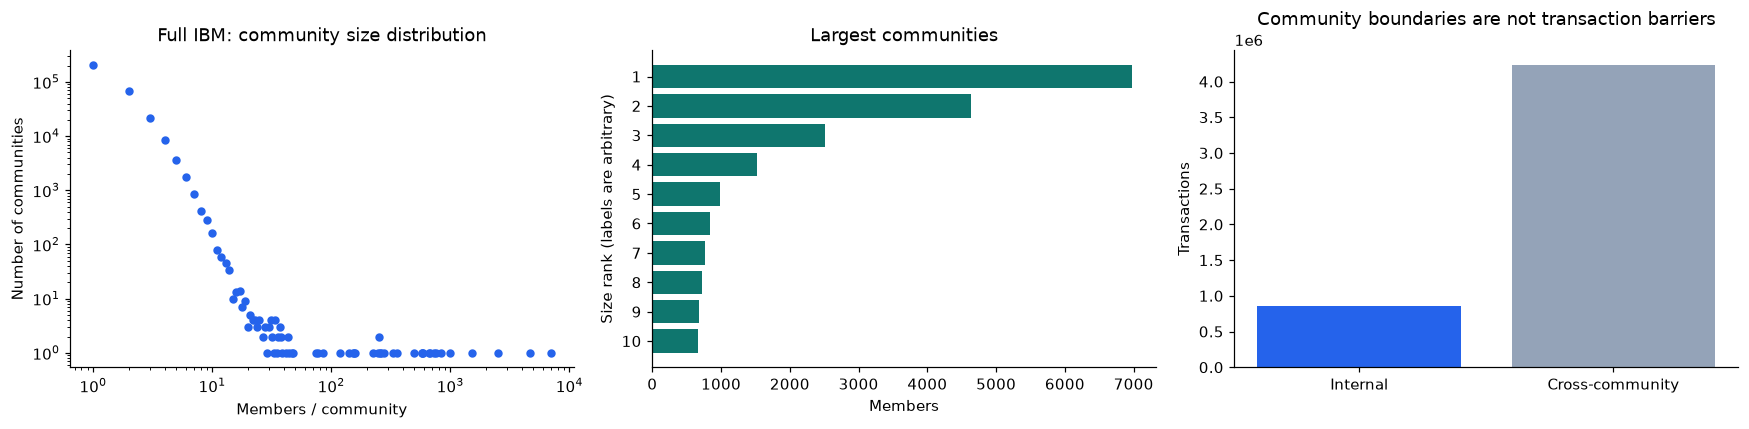

Internal edges: 16.79%
Fraud labels trong community là profile sau LPA, không chứng minh một fraud ring.


In [35]:
# Đồ thị được tính từ chính lần full LPA ở trên.
size_distribution = full_summary.groupBy('member_count').count().orderBy('member_count').toPandas()
top_communities = full_overview.limit(10).toPandas()
fig,axes = plt.subplots(1,3,figsize=(16,4))
axes[0].scatter(size_distribution.member_count,size_distribution['count'],color='#2563eb',s=20)
axes[0].set(xscale='log',yscale='log',xlabel='Members / community',ylabel='Number of communities',
            title='Full IBM: community size distribution')
axes[1].barh([str(i+1) for i in range(len(top_communities))],top_communities.member_count,color='#0f766e')
axes[1].invert_yaxis()
axes[1].set(xlabel='Members',ylabel='Size rank (labels are arbitrary)',title='Largest communities')
axes[2].bar(['Internal','Cross-community'],[full_lpa_metrics['internal_edges'],
    full_lpa_metrics['cross_edges']],color=['#2563eb','#94a3b8'])
axes[2].set(ylabel='Transactions',title='Community boundaries are not transaction barriers')
plt.tight_layout()
plt.show()
print(f"Internal edges: {full_lpa_metrics['internal_edges']/full_lpa_metrics['edges']:.2%}")
print('Fraud labels trong community là profile sau LPA, không chứng minh một fraud ring.')
full_labels.unpersist()
full_summary.unpersist()
full_amounts.unpersist()
spark.catalog.clearCache()


### Hai lần sample: so thành viên, bỏ qua số label

Đại diện mỗi community bằng ID tài khoản nhỏ nhất rồi so account→anchor. `same_partition=False` là quan sát stability, không tự động là lỗi. Hai lần giống nhau cũng không chứng minh luôn deterministic. Kiểm tra sample này tách biệt kết quả full ở trên.


In [36]:
# Canonicalize theo min account ID; so thành viên thay vì số label.
# Production: src/ibm_aml/verify_communities.py

def compare_partition_frames(current, previous) -> dict:
    """Compare membership using each community's minimum account ID, ignoring label numbers."""
    frames = []
    for assignments in (current, previous):
        frame = numeric(assignments, ["label"])
        unique_keys(frame, ["id"], "partition")
        canonical = frame.groupBy("label").agg(F.min("id").alias("community_anchor"))
        frames.append(frame.join(canonical, "label").select("id", "community_anchor"))
    same_keys(frames[0], frames[1], ["id"], "partition account set")
    joined = frames[0].join(frames[1].withColumnRenamed("community_anchor", "previous_anchor"), "id")
    changed = joined.where(F.col("community_anchor") != F.col("previous_anchor")).count()
    return {"same_partition": changed == 0, "accounts_with_changed_canonical_community": changed,
            "accounts": joined.count(), "interpretation": "observed comparison; differences do not invalidate LPA"}


In [37]:
ibm_sample = load_graph(spark,str(REPO_ROOT/'data/processed/sample/ibm_aml'))
sample_labels_1 = run_lpa(ibm_sample,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'sample_1')
sample_labels_2 = run_lpa(ibm_sample,spark,max_iter=5,checkpoint_dir=Path(runtime_temp.name)/'sample_2')
for assignments in (sample_labels_1,sample_labels_2):
    unique_keys(assignments,['id'],'sample assignments')
    same_keys(assignments,ibm_sample.vertices,['id'],'sample coverage')
    numeric(assignments,['label'])
stability = compare_partition_frames(sample_labels_2,sample_labels_1)
display(pd.DataFrame([stability]))
sample_labels_1.unpersist()
sample_labels_2.unpersist()
spark.catalog.clearCache()
checks_passed['Task 4 IBM: two live sample runs and membership comparison'] = True



[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-ibm-aml-hi-small-0vfzh2un\sample_1 ...


[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 119,043

[*] Đang thực thi LPA trên IBM AML (maxIter=5) với checkpoint tại: C:\Users\ADMIN\AppData\Local\Temp\graphguard-ibm-aml-hi-small-0vfzh2un\sample_2 ...


[+] LPA IBM AML hoàn tất. Tổng số đỉnh đã gán nhãn: 119,043


,same_partition,accounts_with_changed_canonical_community,accounts,interpretation
0,True,0,119043,observed comparison; differences do not invali...


### Các phản ví dụ checker phải từ chối

Account trùng/thiếu, label null/không nguyên, amount NaN và cột amount tổng hợp không tách currency. Kiểm tra trong bộ nhớ, không tạo test CSV.


In [38]:
def expect_rejection(label,operation):
    try:
        operation()
    except ValueError as error:
        return {'case':label,'status':'PASS: rejected','reason':str(error)}
    raise AssertionError('Checker không từ chối: '+label)

# Phản ví dụ currency đi qua chính checker đầy đủ, không chỉ qua một assert riêng.
review_vertices = spark.sql("SELECT * FROM VALUES ('A','1',0.0),('B','1',0.0) AS v(id,bank_id,balance)")
review_edges = spark.sql("SELECT 'A' AS src,'B' AS dst,0 AS isFraud,10.0 AS amount,'US Dollar' AS payment_currency")
review_graph = GraphFrame(review_vertices,review_edges)
review_assignments = review_vertices.select('id').withColumn('label',F.lit(1).cast('long'))
review_summary = spark.sql("SELECT CAST(1 AS BIGINT) AS label,2 AS member_count,1 AS unique_banks_count,"
    "0.0 AS avg_balance,1 AS total_tx_count,0 AS laundering_tx_count,1 AS internal_tx_count,"
    "0 AS internal_laundering_count,0.0 AS laundering_rate")
review_amounts = spark.sql("SELECT CAST(1 AS BIGINT) AS label,'US Dollar' AS payment_currency,"
    "1 AS total_tx_count,10.0 AS total_tx_amount")

one = spark.sql("SELECT 'A' AS id,'1' AS label")
two = spark.sql("SELECT * FROM VALUES ('A','1'),('B','2') AS t(id,label)")
rejections = [
    expect_rejection('duplicate account',lambda:unique_keys(one.unionByName(one),['id'],'assignments')),
    expect_rejection('missing account',lambda:same_keys(one,two,['id'],'assignments')),
    expect_rejection('null label',lambda:numeric(spark.sql("SELECT CAST(NULL AS STRING) AS label"),['label'])),
    expect_rejection('fractional label',lambda:numeric(spark.sql("SELECT '1.5' AS label"),['label'])),
    expect_rejection('NaN amount',lambda:numeric(spark.sql("SELECT 'NaN' AS amount"),['amount'],integral=False)),
    expect_rejection('mixed-currency summary field',lambda:verify_community_frames(
        review_graph,review_assignments,review_summary.withColumn('total_tx_amount',F.lit(10.0)),
        review_summary,review_amounts)),
]
assert 'payment_currency' in rejections[-1]['reason']
display(pd.DataFrame(rejections))
checks_passed['Checker rejects malformed keys, labels and amounts'] = True


[PASS] Exact account coverage and non-null integer labels: 2


,case,status,reason
0,duplicate account,PASS: rejected,assignments: duplicate keys
1,missing account,PASS: rejected,assignments: incomplete or foreign keys (missi...
2,null label,PASS: rejected,Invalid numeric values in ['label']
3,fractional label,PASS: rejected,Invalid numeric values in ['label']
4,NaN amount,PASS: rejected,Invalid numeric values in ['amount']
5,mixed-currency summary field,PASS: rejected,Ambiguous total_tx_amount in community summary...


### Hàm xuất CSV production — đầy đủ để đọc, không gọi trong notebook

CLI bàn giao assignments, top 50, **toàn bộ** summary và amount theo currency. Cell dưới chỉ định nghĩa nguyên hàm export để thầy đọc được ngay; không gọi hàm này và không tạo các file CSV đó.


In [39]:
# Toàn bộ export production; chỉ định nghĩa để đọc, không ghi file từ notebook.
# Production: src/ibm_aml/community_detection.py

def export_results(lpa_vertices, summary_df, output_dir: Path, graph: GraphFrame | None = None):
    """Xuất các file CSV độc lập theo chuẩn UTF-8 BOM."""
    output_dir.mkdir(parents=True, exist_ok=True)

    communities_path = output_dir / COMMUNITIES_FILENAME
    summary_path = output_dir / COMMUNITY_SUMMARY_FILENAME

    print(f"\n=== [Task 4] Xuất kết quả bàn giao IBM AML ===")

    # 1. Xuất file communities.csv
    export_cols = ["id", "label"]
    if "bank_id" in lpa_vertices.columns:
        export_cols.insert(1, "bank_id")
    if "account_type" in lpa_vertices.columns:
        export_cols.append("account_type")

    pdf_communities = (
        lpa_vertices
        .select(*export_cols)
        .orderBy(F.asc("label"), F.asc("id"))
        .toPandas()
    )
    pdf_communities.to_csv(communities_path, index=False, encoding="utf-8-sig")
    print(f"  [OK] Đã ghi danh sách cộng đồng IBM AML: {communities_path} ({len(pdf_communities):,} accounts)")

    # 2. Xuất file community_summary.csv
    pdf_summary = summary_df.limit(50).toPandas()
    pdf_summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
    print(f"  [OK] Đã ghi bảng tổng hợp cộng đồng IBM AML: {summary_path} (Top {len(pdf_summary)} communities)")

    # Keep the top-50 report above, and export a complete table for reconciliation.
    def write_spark_csv(frame, path):
        with path.open("w", newline="", encoding="utf-8-sig") as stream:
            writer = csv.writer(stream, lineterminator="\n")
            writer.writerow(frame.columns)
            for row in frame.toLocalIterator():
                writer.writerow(list(row))

    write_spark_csv(summary_df, output_dir / COMMUNITY_SUMMARY_ALL_FILENAME)
    if graph is not None:
        labels = lpa_vertices.select(F.col("id").alias("src"), "label")
        amounts = (graph.edges.join(labels, on="src", how="inner")
                   .groupBy("label", "payment_currency")
                   .agg(F.count("*").alias("total_tx_count"),
                        F.sum("amount").alias("total_tx_amount"))
                   .orderBy("label", "payment_currency"))
        write_spark_csv(amounts, output_dir / COMMUNITY_AMOUNTS_FILENAME)
    print("  [OK] Đã ghi toàn bộ community summary và amount theo từng payment_currency")


### Kết luận thực nghiệm IBM

- ETL full được dựng lại từ raw, qua bộ kiểm tra contract/integrity và đối chiếu Parquet hai chiều có tính bội số.
- Audit trên các cạnh gắn nhãn có **7.473 raw rows**, **54 cycle tài khoản có hướng**, **2.491 tổ hợp cạnh**, **45 bộ ba không xét chiều**.
- Query không dùng nhãn, yêu cầu cả ba cạnh bằng USD và >10.000, cho **0 kết quả**. Không so trực tiếp hai query để kết luận khả năng phát hiện.
- Cycle minh họa từ Patterns dùng **Saudi Riyal**, có thời gian tăng và cạnh khớp input; không gọi đó là cycle USD.
- LPA full được kiểm tra độc lập; amount tách theo currency. Hai lần sample chỉ chứng minh quan sát stability sample.
- Community chứa fraud labels là profile sau thuật toán, không tự chứng minh một fraud ring.

- Detector bổ sung tìm cycle **không lọc nhãn**, chọn rule trên validation và báo test theo cạnh đóng vòng; xem bảng metrics/TP/FP/FN ở mục 4. Audit nhãn 54 vòng phía trên không được dùng thay hiệu quả detector.


## 6 · Đối chiếu code và chốt lần chạy IBM

AST của các hàm trong notebook phải khớp source production. Bảng sau ghi module/hàm/hash để nhận biết phiên bản đã chạy. CLI export CSV được giữ nguyên hàm để đọc nhưng không gọi; nghiệm thu trong notebook dùng DataFrame trong bộ nhớ.


In [40]:
notebook_document = json.loads(NOTEBOOK_PATH.read_text(encoding='utf-8'))
visible_functions = {}
for cell in notebook_document['cells']:
    if cell['cell_type'] == 'code':
        for node in ast.parse(''.join(cell['source'])).body:
            if isinstance(node,ast.FunctionDef):
                visible_functions[node.name] = node
source_audit = []
for record in notebook_document['metadata']['graphguard_sources']:
    source = (REPO_ROOT/record['path']).read_text(encoding='utf-8')
    actual_functions = {n.name:n for n in ast.parse(source).body if isinstance(n,ast.FunctionDef)}
    for name in record['functions']:
        assert ast.dump(visible_functions[name],include_attributes=False) == ast.dump(
            actual_functions[name],include_attributes=False), f'Source drift: {record["path"]}:{name}'
    source_audit.append({'module':record['path'],'functions':', '.join(record['functions']),
                         'sha256':hashlib.sha256(source.encode('utf-8')).hexdigest(),'status':'MATCH'})
display(pd.DataFrame(source_audit))
checks_passed['All displayed production functions match repository AST'] = True


,module,functions,sha256,status
0,src/common/graph_utils.py,load_graph,b656fc4d7767fa1a3cc9bdb8e66101b0f6272daf01d586...,MATCH
1,src/motif/toy_cycle.py,"build_toy_graph, find_three_node_cycles, cycle...",44caa76842030eb834f9e854fd7f8b18cd5aabf2498f47...,MATCH
2,src/ibm_aml/etl.py,"validate_csv_header, invalid_required_values, ...",2602afff5b9d4bf22101f6af3b460c3377add35ce0c1af...,MATCH
3,src/ibm_aml/etl.py,"build_ibm_vertices, sample_ibm_edges",2602afff5b9d4bf22101f6af3b460c3377add35ce0c1af...,MATCH
4,src/common/graph_utils.py,check_integrity,b656fc4d7767fa1a3cc9bdb8e66101b0f6272daf01d586...,MATCH
5,tests/test_ibm_aml_etl.py,run_tests,6b7d4ab67c29e898f178e08bd783aae7974238149ea258...,MATCH
6,src/ibm_aml/motif_finding.py,"directed_account_cycles, find_usd_cycles, find...",d889aaed482e2c45ae2d9722b41d5b0ae1efd638286c5a...,MATCH
7,src/ibm_aml/visualize.py,"read_three_account_cycles, select_example",0203b99ca86b358e3eea0a6ff4ce9f253c7bbeb24f877b...,MATCH
8,src/ibm_aml/community_detection.py,run_lpa,ddfd4c3cb584ed94b1b3e56232074e2dd9aff4e0e659d4...,MATCH
9,src/ibm_aml/community_detection.py,analyze_communities,ddfd4c3cb584ed94b1b3e56232074e2dd9aff4e0e659d4...,MATCH


In [41]:
assert all(checks_passed.values())
finished_at = datetime.now(timezone.utc)
display(pd.DataFrame([{'check': name, 'status': 'PASS'} for name in checks_passed]))
display(pd.DataFrame([{
    'dataset': 'IBM AML HI-Small', 'scope': 'full',
    'started_utc': started_at.isoformat(), 'finished_utc': finished_at.isoformat(),
    'elapsed_seconds': round(time.perf_counter() - started_clock, 1),
    'review_scope': 'IBM ETL, Task 3 IBM, Task 4 IBM',
    'stability_scope': 'IBM sample, 2 live runs',
    **runtime,
}]))
# Dừng Spark trước khi dọn checkpoint tạm ngoài repository.
spark.catalog.clearCache()
spark.stop()
runtime_temp.cleanup()
print('PASS — IBM AML HI-Small: toàn bộ notebook đã chạy, output và hình đã được lưu.')


,check,status
0,Windows Python 3.12 / JDK 17 / dependencies,PASS
1,"IBM ETL: raw contract, integrity and exact Par...",PASS
2,Toy graph.find: 3 rotations / 1 cycle,PASS
3,"IBM motifs: rotations, multiplicity and all-ed...",PASS
4,"Task 3 IBM full: rotations, multiplicity, curr...",PASS
5,"IBM documented cycle: source, time order and o...",PASS
6,"IBM: label-blind causal cycles, currency quant...",PASS
7,Task 4 IBM full: independent complete reconcil...,PASS
8,Task 4 IBM: two live sample runs and membershi...,PASS
9,"Checker rejects malformed keys, labels and amo...",PASS


,dataset,scope,started_utc,finished_utc,elapsed_seconds,review_scope,stability_scope,system,python,spark,graphframes,java,master,driver_memory,session_timezone
0,IBM AML HI-Small,full,2026-10-18T16:18:40.966182+00:00,2026-10-18T16:22:54.825387+00:00,253.9,"IBM ETL, Task 3 IBM, Task 4 IBM","IBM sample, 2 live runs",Windows,3.12.10,3.5.1,0.12.2,17.0.20.1,local[4],8g,Asia/Saigon


PASS — IBM AML HI-Small: toàn bộ notebook đã chạy, output và hình đã được lưu.
